# Do some buying leagues systematically overpay for players?
**Data Management and Analysis – Sapienza** · Transfermarkt transfers of the 7 big European leagues, seasons 2009–2021

**Main question.** Do some buying leagues systematically overpay for players?

* **Relative overpay**: a league pays a higher fee than other leagues for a *comparable* player (same market value, age, position, season).
* **Absolute overpay**: the predicted fee / market-value ratio for a *standard player* bought by that league is above 1.
* **Systematically**: the league gap appears in every age band, every position group and across seasons, not only in one subgroup.

**Branches.** (1) age · (2) position · deal size · (3) stability over time · (4) origin of the player and the country transfer network · then robustness.

**Toolkit used (course methods only).** Log transforms, z-scores, binning, dummy encoding, feature engineering, Pearson/Spearman correlation, two-sample t-test, chi-square test, one-way ANOVA + Tukey HSD, simple/multiple linear regression with R² and predictions, network science. The only extension is HC3 robust standard errors.

## 1. Setup, load and cleaning funnel
**Question:** which transfers can we use to compare a fee with the player's market value, and how many survive each cleaning step?

In [1]:
# --- libraries (course toolkit only) ---
import os
import numpy as np                       # numbers, logs, exponentials
import pandas as pd                      # tables
import matplotlib.pyplot as plt          # figures
from scipy import stats                  # z-scores, t-test, ANOVA, chi-square, correlations
import statsmodels.formula.api as smf    # linear regression written as formulas
import statsmodels.api as sm             # Q-Q plot
from statsmodels.stats.multicomp import pairwise_tukeyhsd   # Tukey HSD after ANOVA
import networkx as nx                    # network science
import warnings
# scipy prints a harmless numerical-integration warning while computing Tukey p-values; hide it
warnings.filterwarnings("ignore", message="The integral is probably divergent")

# --- reproducibility: fixed seed, relative paths ---
SEED = 42
np.random.seed(SEED)
DATA_PATH = "../data/transfers.csv"                  # run from notebooks/; see data/README.md
FIG_DIR, TAB_DIR = "../figures", "../tables"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

# --- large fonts so figures stay readable on a slide ---
plt.rcParams.update({
    "font.size": 14, "axes.titlesize": 17, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
})
# fixed colour order (one colour per series, always in this order)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
GREY = "#8a8a85"

# league code -> country name (used as the category label in the models)
LEAGUE_NAME = {"GB1": "England", "ES1": "Spain", "IT1": "Italy", "L1": "Germany",
               "FR1": "France", "PO1": "Portugal", "NL1": "Netherlands"}
# country name -> name of the league, for figure labels
LEAGUE_LABEL = {"England": "England (PL)", "Spain": "Spain (LaLiga)", "Italy": "Italy (Serie A)",
                "Germany": "Germany (Bundesliga)", "France": "France (Ligue 1)",
                "Portugal": "Portugal", "Netherlands": "Netherlands"}

def save_fig(fig, name):
    """Save a figure as PNG (dpi=150) in figures/ and show it in the notebook."""
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()

def save_table(table, name, index=True):
    """Save a table as CSV in tables/."""
    table.to_csv(os.path.join(TAB_DIR, name), index=index)

def pct(b):
    """Turn a coefficient on log(fee) into a % difference in the fee: (exp(b) - 1) * 100."""
    return (np.exp(b) - 1) * 100

def fmt_p(table):
    """Copy of a table with p-value columns written in scientific notation (so tiny p's do not print as 0.0)."""
    t = table.copy()
    for c in [c for c in t.columns if c == "p" or str(c).startswith("p_")]:
        t[c] = t[c].map(lambda v: "" if pd.isna(v) else f"{v:.1e}")
    return t

In [2]:
# load the raw file (never modified)
raw = pd.read_csv(DATA_PATH)
print(f"raw rows: {len(raw):,}  | columns: {raw.shape[1]}")
print("seasons:", raw["season"].min(), "-", raw["season"].max())
print("leagues:", sorted(raw["league"].unique()))

raw rows: 70,006  | columns: 23
seasons: 2009 - 2021
leagues: ['ES1', 'FR1', 'GB1', 'IT1', 'L1', 'NL1', 'PO1']


In [3]:
# Cleaning funnel: apply one filter at a time and record the row count after each step
funnel = [("raw file", len(raw))]

d = raw[raw["dir"] == "in"]                         # keep the BUYING side, so each transfer is counted once
funnel.append(("dir == 'in' (buying league)", len(d)))

d = d[(d["is_loan"] == False) & (d["is_loan_end"] == False)]   # permanent moves only (loans have no comparable fee)
funnel.append(("permanent (no loan, no loan end)", len(d)))
pool = d.copy()                                     # kept for the disclosure-bias check in section 9

d = d[d["transfer_fee_amnt"] > 0]                   # a positive fee was paid and disclosed (NaN and 0 drop out)
funnel.append(("fee > 0", len(d)))

d = d[d["market_val_amnt"] > 0]                     # a market value exists to compare the fee with
funnel.append(("market value > 0", len(d)))

d = d[d["player_age"].between(15, 45)]              # plausible professional ages (also drops missing ages)
funnel.append(("15 <= age <= 45", len(d)))

for step, n in funnel:
    print(f"{step:35s} {n:>7,}")

raw file                             70,006
dir == 'in' (buying league)          31,934
permanent (no loan, no loan end)     17,983
fee > 0                               7,217
market value > 0                      6,097
15 <= age <= 45                       6,097


In [4]:
# Outlier rule on the premium = log(fee) - log(market value)
# (the log turns "fee is 3x the value" and "fee is 1/3 of the value" into +1.1 and -1.1: symmetric)
d = d.copy()
d["premium"] = np.log(d["transfer_fee_amnt"]) - np.log(d["market_val_amnt"])
d_pre = d.copy()                                    # sample before the outlier rule (used in robustness, section 9)

# z-score = how many standard deviations a deal is from the average premium
d["z_premium"] = stats.zscore(d["premium"])
outliers = d[d["z_premium"].abs() > 3]              # empirical rule: |z| > 3 is an outlier
d = d[d["z_premium"].abs() <= 3].copy()
funnel.append(("outlier rule |z(premium)| <= 3", len(d)))

print(f"premium mean = {d_pre['premium'].mean():.3f}, sd = {d_pre['premium'].std():.3f}")
print(f"outliers dropped: {len(outliers)}  -> final sample: {len(d):,}\n")
print("outliers by league:")
print(outliers["league"].map(LEAGUE_NAME).value_counts().to_string())
print("\n10 largest fees among the dropped outliers:")
top10 = outliers.nlargest(10, "transfer_fee_amnt")[
    ["league", "season", "player_name", "team_name", "transfer_fee_amnt", "market_val_amnt", "z_premium"]]
print(top10.to_string(index=False))
save_table(outliers.drop(columns=["z_premium"]), "outliers_dropped.csv", index=False)

premium mean = 0.378, sd = 1.457
outliers dropped: 34  -> final sample: 6,063

outliers by league:
league
Italy          19
England         5
Portugal        3
Netherlands     3
Spain           2
Germany         2

10 largest fees among the dropped outliers:
league  season       player_name            team_name  transfer_fee_amnt  market_val_amnt  z_premium
   IT1    2011 Davide Bertoncini            Genoa CFC        550000000.0         300000.0   4.898493
   IT1    2009      Simone Pesce       Calcio Catania        500000000.0         200000.0   5.111391
   IT1    2009      Andrea Cocco      Cagliari Calcio        500000000.0          75000.0   5.784656
   IT1    2010      Danilo Russo            Genoa CFC        500000000.0         100000.0   5.587184
   IT1    2010   Stefano Guberti              AS Roma        500000000.0          50000.0   6.062977
   IT1    2011  Paolo Dellafiore   Novara Calcio 1908        500000000.0          25000.0   6.538770
   IT1    2012   Luca Berardocco D

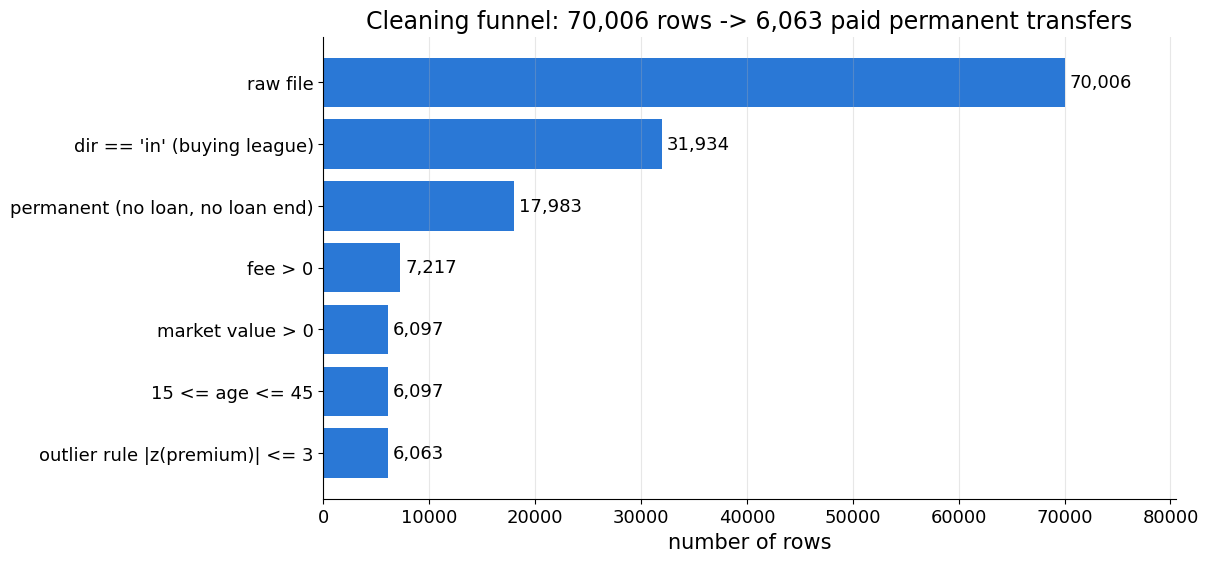

In [5]:
# Save the funnel as a table and a simple bar chart
funnel_df = pd.DataFrame(funnel, columns=["step", "rows"])
save_table(funnel_df, "cleaning_funnel.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(funnel_df["step"][::-1], funnel_df["rows"][::-1], color=COLORS[0])
for y, n in enumerate(funnel_df["rows"][::-1]):
    ax.text(n + 500, y, f"{n:,}", va="center", fontsize=13)      # print the count next to each bar
ax.set_xlabel("number of rows")
ax.set_title(f"Cleaning funnel: {len(raw):,} rows -> {len(d):,} paid permanent transfers")
ax.set_xlim(0, len(raw) * 1.15)
ax.grid(axis="y", visible=False)
save_fig(fig, "fig01_cleaning_funnel.png")

### Takeaway

* The funnel goes from **70,006** raw rows to **31,934** incoming, **17,983** permanent, **7,217** with a positive fee, **6,097** with a market value. The age filter removes no rows (6,097).
* The z-rule (premium mean 0.378, sd 1.457) drops **34** deals. **19** of them are Italian. The final sample has **6,063** paid permanent transfers.
* Nine of the 10 largest fees among the outliers are **€500–550M Serie A fees** (2009–2013) for players valued between €25k and €500k, so they are corrupted records. The 10th is a €100M fee (2019) for a player valued at €0.8M.

## 2. Feature engineering
**Question:** which variables do we need to compare "similar" players, and are the country names consistent so that domestic/foreign flags are correct?

In [6]:
# Check that country spellings match across the three country columns
# (if "England" were written "ENG" in one column, the domestic flag would be wrong)
team_c = set(d["team_country"])
counter_c = set(d["counter_team_country"])
nation_c = set(raw["player_nation"].dropna())
print("buying countries:", sorted(team_c))
print("buying countries missing from counter_team_country:", sorted(team_c - counter_c))
print("buying countries missing from player_nation:      ", sorted(team_c - nation_c))
print("seller countries in the sample not found among nationalities:",
      sorted(counter_c - nation_c))

# mapping to fix spellings: empty because no mismatch was found above
COUNTRY_FIX = {}
for col in ["team_country", "counter_team_country", "player_nation"]:
    d[col] = d[col].replace(COUNTRY_FIX)

buying countries: ['England', 'France', 'Germany', 'Italy', 'Netherlands', 'Portugal', 'Spain']
buying countries missing from counter_team_country: []
buying countries missing from player_nation:       []
seller countries in the sample not found among nationalities: []


In [7]:
# Position: 16 detailed roles -> 4 groups
POS_GROUP = {"GK": "GK",
             "CB": "DEF", "LB": "DEF", "RB": "DEF", "defence": "DEF",
             "DM": "MID", "CM": "MID", "AM": "MID", "LM": "MID", "RM": "MID", "midfield": "MID",
             "CF": "ATT", "SS": "ATT", "LW": "ATT", "RW": "ATT", "attack": "ATT"}
AGE_ORDER = ["<=21", "22-25", "26-29", "30+"]
AGE3_ORDER = ["<=21", "22-25", "26+"]
POS_ORDER = ["GK", "DEF", "MID", "ATT"]

def make_features(frame, mean_age=None):
    """Add all engineered variables to a copy of the cleaned transfers."""
    f = frame.copy()
    f["league_name"] = f["league"].map(LEAGUE_NAME)
    f["pos_group"] = f["player_pos"].map(POS_GROUP)
    # binning: age into bands (right-closed: 21 -> "<=21", 25 -> "22-25" ...)
    f["age_band"] = pd.cut(f["player_age"], [0, 21, 25, 29, 100], labels=AGE_ORDER).astype(str)
    f["age_band3"] = pd.cut(f["player_age"], [0, 21, 25, 100], labels=AGE3_ORDER).astype(str)
    # centred age and its square (for the curved age profile in section 5)
    m = f["player_age"].mean() if mean_age is None else mean_age
    f["age_c"] = f["player_age"] - m
    f["age_c2"] = f["age_c"] ** 2
    # log transforms: fees and values are very right-skewed, logs make them roughly symmetric
    f["log_fee"] = np.log(f["transfer_fee_amnt"])
    f["log_val"] = np.log(f["market_val_amnt"])
    f["premium"] = f["log_fee"] - f["log_val"]                      # > 0 means fee above market value
    f["ratio"] = f["transfer_fee_amnt"] / f["market_val_amnt"]     # same idea on the raw scale
    # origin flags
    f["is_domestic"] = f["team_country"] == f["counter_team_country"]   # bought from a club in the same country
    f["is_foreign_player"] = f["player_nation"] != f["team_country"]    # player's nationality differs from buyer's country
    f["post2016"] = f["season"] >= 2016
    return f

d = make_features(d)
MEAN_AGE = d["player_age"].mean()

# binning by quantiles: market-value quartiles
d["value_tier"], tier_edges = pd.qcut(d["market_val_amnt"], 4, labels=["Q1", "Q2", "Q3", "Q4"], retbins=True)
d["value_tier"] = d["value_tier"].astype(str)
TIER_ORDER = ["Q1", "Q2", "Q3", "Q4"]

assert d["pos_group"].isna().sum() == 0, "unmapped position"
assert d[["league_name", "age_band", "age_band3"]].isna().sum().sum() == 0
print(f"mean age = {MEAN_AGE:.2f}")
print("value-tier edges (EUR):", [f"{e:,.0f}" for e in tier_edges])
print(f"share is_domestic = True:       {d['is_domestic'].mean():.1%}")
print(f"share is_foreign_player = True: {d['is_foreign_player'].mean():.1%}")
print(f"share post2016 = True:          {d['post2016'].mean():.1%}")

mean age = 23.32
value-tier edges (EUR): ['10,000', '600,000', '2,000,000', '7,000,000', '160,000,000']
share is_domestic = True:       45.7%
share is_foreign_player = True: 69.8%
share post2016 = True:          54.6%


In [8]:
# Crosstabs: how many transfers in each league x age band and league x position cell
ct_age = pd.crosstab(d["league_name"], d["age_band"], margins=True).reindex(columns=AGE_ORDER + ["All"])
ct_pos = pd.crosstab(d["league_name"], d["pos_group"], margins=True).reindex(columns=POS_ORDER + ["All"])
print("league x age band\n", ct_age, "\n")
print("league x position group\n", ct_pos)
save_table(ct_age, "crosstab_league_age.csv")
save_table(ct_pos, "crosstab_league_pos.csv")

league x age band
 age_band     <=21  22-25  26-29  30+   All
league_name                               
England       330    510    248   43  1131
France        269    374    166   31   840
Germany       337    427    143   21   928
Italy         551    624    290  101  1566
Netherlands   165    172     48    4   389
Portugal      116    211     66    9   402
Spain         165    349    231   62   807
All          1933   2667   1192  271  6063 

league x position group
 pos_group     GK   DEF   MID   ATT   All
league_name                             
England       85   357   303   386  1131
France        44   244   236   316   840
Germany       62   273   271   322   928
Italy        100   517   493   456  1566
Netherlands   23   101   114   151   389
Portugal      23   115   132   132   402
Spain         59   242   206   300   807
All          396  1849  1755  2063  6063


### Takeaway

* The 7 buying countries are spelled the same way in `team_country`, `counter_team_country` and `player_nation`, and every seller country in the sample also appears as a nationality. No mapping fix was needed (`COUNTRY_FIX` is empty).
* Shares: **45.7 %** domestic purchases, **69.8 %** foreign players, **54.6 %** of deals from 2016 onward. The mean age is 23.32.
* Market-value quartile edges are €0.6M, €2M and €7M.
* The smallest cells are Netherlands aged 30+ (**4**), Portugal aged 30+ (**9**), and Netherlands and Portugal goalkeepers (**23** each). The 30+ band has only 271 deals, which is why the subgroup models use `age_band3` (26+).

## 3. Dependent variable
**Question:** should we model the raw fee/value ratio or its log (the premium)?

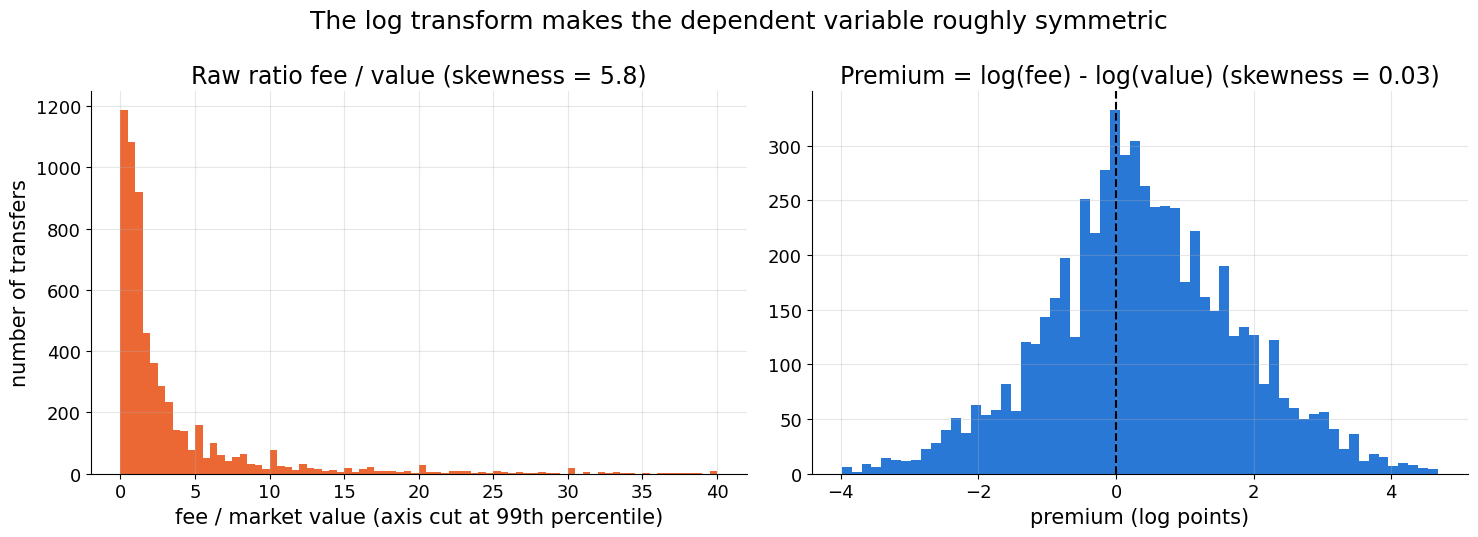

median ratio (all transfers): 1.33
share of transfers with fee > value: 59.0%

median ratio by buying league:
league_name
Italy          1.83
England        1.70
Spain          1.28
Germany        1.20
France         1.18
Portugal       1.00
Netherlands    0.75


In [9]:
# Compare the shape of the raw ratio and of the log premium (skewness 0 = symmetric)
sk_ratio, sk_prem = stats.skew(d["ratio"]), stats.skew(d["premium"])

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].hist(d["ratio"], bins=80, range=(0, d["ratio"].quantile(0.99)), color=COLORS[1])
ax[0].set_title(f"Raw ratio fee / value (skewness = {sk_ratio:.1f})")
ax[0].set_xlabel("fee / market value (axis cut at 99th percentile)")
ax[0].set_ylabel("number of transfers")
ax[1].hist(d["premium"], bins=60, color=COLORS[0])
ax[1].axvline(0, color="black", ls="--", lw=1.5)                # 0 = fee equals market value
ax[1].set_title(f"Premium = log(fee) - log(value) (skewness = {sk_prem:.2f})")
ax[1].set_xlabel("premium (log points)")
fig.suptitle("The log transform makes the dependent variable roughly symmetric", fontsize=18)
fig.tight_layout()
save_fig(fig, "fig02_ratio_vs_premium.png")

print(f"median ratio (all transfers): {d['ratio'].median():.2f}")
print(f"share of transfers with fee > value: {(d['ratio'] > 1).mean():.1%}")
print("\nmedian ratio by buying league:")
print(d.groupby("league_name")["ratio"].median().sort_values(ascending=False).round(2).to_string())

### Takeaway

* The raw ratio is strongly right-skewed (**skewness 5.80**). The log premium is almost symmetric (**skewness 0.03**), so we model log values.
* The median ratio is **1.33**, and **59.0 %** of deals have fee > value.
* **Not all leagues pay above market value on average.** The median ratio is above 1 in five leagues (Italy 1.83, England 1.70, Spain 1.28, Germany 1.20, France 1.18). Portugal is exactly **1.00** and the Netherlands is below 1 (**0.75**).
* A raw ratio above 1 is common, and the leagues differ in the kind of player they buy. So "overpay" is defined **relative to other leagues for a comparable player** (4b) and through the **predicted ratio for one standard player** (4c).

## 4. MAIN QUESTION: do some buying leagues systematically overpay?
### 4a. Unconditional comparison
**Question:** before any controls, do average premiums differ between buying leagues?

                n  median_ratio  mean_premium  median_premium
league_name                                                  
Italy        1566         1.829         0.593           0.604
England      1131         1.700         0.680           0.531
Spain         807         1.280         0.322           0.247
Germany       928         1.200         0.223           0.182
France        840         1.176         0.220           0.162
Portugal      402         1.000         0.057           0.000
Netherlands   389         0.750        -0.316          -0.288


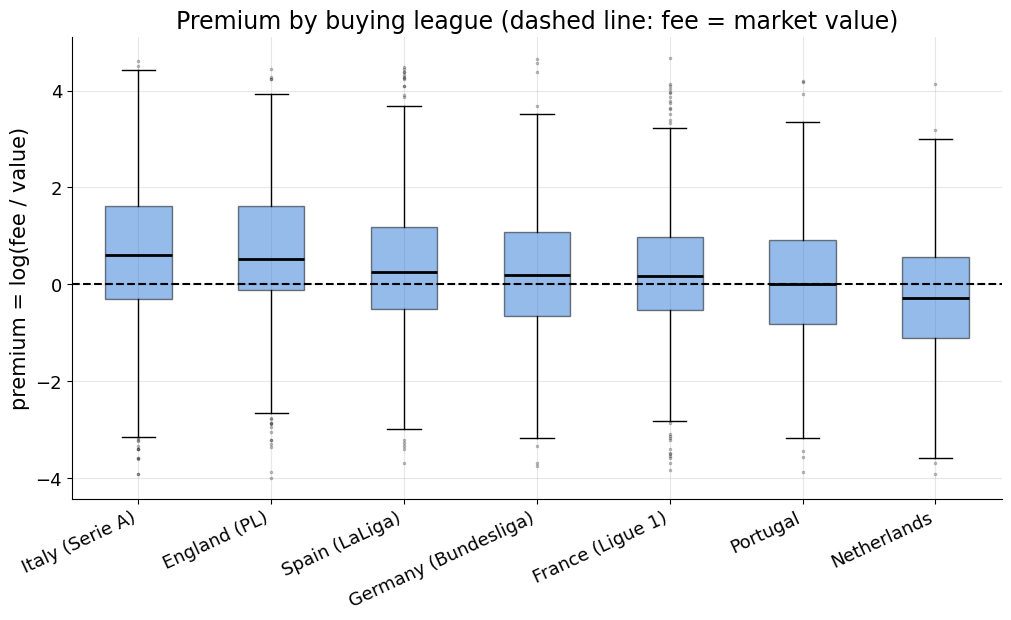

In [10]:
# Summary per league: size, median ratio, mean premium
by_league = (d.groupby("league_name")
               .agg(n=("premium", "size"), median_ratio=("ratio", "median"),
                    mean_premium=("premium", "mean"), median_premium=("premium", "median"))
               .sort_values("median_premium", ascending=False))
print(by_league.round(3).to_string())
save_table(by_league, "premium_by_league.csv")

# Boxplot, leagues ordered by median premium; dashed line = fee equals value
order = by_league.index.tolist()
fig, ax = plt.subplots(figsize=(12, 6))
ax.boxplot([d.loc[d["league_name"] == l, "premium"] for l in order],
           patch_artist=True, boxprops=dict(facecolor=COLORS[0], alpha=0.5),
           medianprops=dict(color="black", lw=2), flierprops=dict(marker=".", markersize=3, alpha=0.3))
ax.axhline(0, color="black", ls="--", lw=1.5)
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels([LEAGUE_LABEL[l] for l in order], rotation=25, ha="right")
ax.set_ylabel("premium = log(fee / value)")
ax.set_title("Premium by buying league (dashed line: fee = market value)")
save_fig(fig, "fig03_premium_by_league_box.png")

In [11]:
# One-way ANOVA: H0 = all leagues have the same mean premium
anova_league = stats.f_oneway(*[d.loc[d["league_name"] == l, "premium"] for l in order])
print(f"ANOVA premium ~ league: F = {anova_league.statistic:.2f}, p = {anova_league.pvalue:.2e}")

# Tukey HSD: which PAIRS of leagues differ (controls the error rate across all 21 pairs)
tukey_league = pairwise_tukeyhsd(d["premium"], d["league_name"], alpha=0.05)
def tukey_df(res):
    """Convert a Tukey result into a DataFrame."""
    tab = res.summary().data
    return pd.DataFrame(tab[1:], columns=tab[0])
tk_league = tukey_df(tukey_league)
print(tk_league.to_string(index=False))
print(f"\nsignificant pairs: {tk_league['reject'].sum()} of {len(tk_league)}")
save_table(tk_league, "tukey_league.csv", index=False)

ANOVA premium ~ league: F = 40.24, p = 2.67e-48


     group1      group2  meandiff  p-adj   lower   upper  reject
    England      France   -0.4594 0.0000 -0.6428 -0.2759    True
    England     Germany   -0.4570 0.0000 -0.6354 -0.2787    True
    England       Italy   -0.0862 0.6704 -0.2434  0.0709   False
    England Netherlands   -0.9960 0.0000 -1.2327 -0.7593    True
    England    Portugal   -0.6227 0.0000 -0.8565 -0.3889    True
    England       Spain   -0.3581 0.0000 -0.5437 -0.1726    True
     France     Germany    0.0023 1.0000 -0.1895  0.1941   False
     France       Italy    0.3731 0.0000  0.2009  0.5453    True
     France Netherlands   -0.5366 0.0000 -0.7836 -0.2896    True
     France    Portugal   -0.1633 0.4325 -0.4076  0.0809   False
     France       Spain    0.1012 0.7424 -0.0973  0.2997   False
    Germany       Italy    0.3708 0.0000  0.2040  0.5376    True
    Germany Netherlands   -0.5389 0.0000 -0.7822 -0.2957    True
    Germany    Portugal   -0.1656 0.3945 -0.4061  0.0748   False
    Germany       Spain  

### Takeaway

* Mean premium by league: England 0.680, Italy 0.593, Spain 0.322, Germany 0.223, France 0.220, Portugal 0.057, Netherlands −0.316. By median premium, Italy (0.604) ranks above England (0.531).
* One-way ANOVA rejects equal means: **F = 40.24, p = 2.7 × 10⁻⁴⁸**.
* Tukey HSD: **15 of 21** pairs differ. The pairs that do **not** differ are England–Italy (p = 0.67) and the middle group France, Germany, Spain and Portugal (France–Germany, France–Spain, France–Portugal, Germany–Spain, Germany–Portugal).
* These are raw comparisons. They do not yet hold the player's value, age or position fixed.

### 4b. Main model: same player, different buying league
**Question:** for a comparable player (same market value, position, age band, season, domestic/foreign deal), do some leagues pay a higher fee?

Model (multiple linear regression, OLS):
`log_fee ~ league (ref. Netherlands) + log_val + position (ref. ATT) + age band (ref. <=21) + season + is_domestic`

Categorical variables enter as dummies (one-hot with one reference category dropped). Because the outcome is in logs, a dummy coefficient *b* means the fee is **(exp(b) − 1) × 100 %** higher than for the reference category.

**HC3 robust standard errors:** HC3 standard errors stay valid even if the spread of the residuals differs across observations (non-constant variance), so we report them next to the normal ones as a check.

In [12]:
LEAGUE_REF = "Netherlands"
MAIN_FORMULA = ("log_fee ~ C(league_name, Treatment('Netherlands')) + log_val"
                " + C(pos_group, Treatment('ATT')) + C(age_band, Treatment('<=21'))"
                " + C(season) + is_domestic")

main = smf.ols(MAIN_FORMULA, data=d).fit()                        # normal standard errors
main_hc3 = smf.ols(MAIN_FORMULA, data=d).fit(cov_type="HC3")      # same coefficients, robust standard errors
print(f"n = {int(main.nobs):,}   R^2 = {main.rsquared:.3f}   adj. R^2 = {main.rsquared_adj:.3f}")

n = 6,063   R^2 = 0.475   adj. R^2 = 0.473


In [13]:
import re
def nice(term):
    """Readable term name: C(league_name, Treatment('Netherlands'))[T.England] -> league_name=England"""
    m = re.match(r"C\((\w+).*\)\[T\.(.+)\]", term)
    if m:
        return f"{m.group(1)}={m.group(2)}"
    return term.replace("[T.True]", "=True")

def coef_table(m, m_rob):
    """Coefficients with normal and HC3 SEs side by side; % effects with 95% CIs for dummies."""
    ci, ci_r = m.conf_int(), m_rob.conf_int()
    t = pd.DataFrame({"term": [nice(x) for x in m.params.index],
                      "b": m.params.values, "se": m.bse.values, "p": m.pvalues.values,
                      "se_HC3": m_rob.bse.values, "p_HC3": m_rob.pvalues.values})
    is_dummy = t["term"].str.contains("league_name=|pos_group=|age_band=|is_domestic=")
    t.loc[is_dummy, "exp_b"] = np.exp(t.loc[is_dummy, "b"])
    t.loc[is_dummy, "pct"] = pct(t.loc[is_dummy, "b"])
    t.loc[is_dummy, "pct_lo"] = pct(ci[0].values[is_dummy])
    t.loc[is_dummy, "pct_hi"] = pct(ci[1].values[is_dummy])
    t.loc[is_dummy, "pct_lo_HC3"] = pct(ci_r[0].values[is_dummy])
    t.loc[is_dummy, "pct_hi_HC3"] = pct(ci_r[1].values[is_dummy])
    return t

main_coefs = coef_table(main, main_hc3)
save_table(main_coefs, "main_model_coefficients.csv", index=False)
show = main_coefs[~main_coefs["term"].str.startswith("C(season")]   # season dummies are controls, saved but not printed
print(fmt_p(show.round(3)).to_string(index=False))

                term      b    se       p  se_HC3   p_HC3  exp_b     pct  pct_lo  pct_hi  pct_lo_HC3  pct_hi_HC3
           Intercept  6.852 0.153 0.0e+00   0.168 0.0e+00    NaN     NaN     NaN     NaN         NaN         NaN
 league_name=England  1.435 0.062 0.0e+00   0.066 0.0e+00  4.200 319.960 271.674 374.520     268.746     378.287
  league_name=France  0.776 0.064 0.0e+00   0.068 0.0e+00  2.173 117.285  91.679 146.311      90.319     148.072
 league_name=Germany  0.796 0.063 0.0e+00   0.067 0.0e+00  2.216 121.609  95.851 150.754      94.416     152.605
   league_name=Italy  0.966 0.059 0.0e+00   0.064 0.0e+00  2.628 162.755 134.000 195.043     131.629     198.063
league_name=Portugal  0.363 0.074 0.0e+00   0.083 0.0e+00  1.437  43.727  24.302  66.187      22.227      69.009
   league_name=Spain  0.852 0.065 0.0e+00   0.070 0.0e+00  2.343 134.323 106.205 166.274     104.088     169.036
       pos_group=DEF -0.258 0.033 0.0e+00   0.033 0.0e+00  0.773 -22.722 -27.609 -17.505     -27

  league     b       p     pct  pct_lo  pct_hi   p_HC3
Portugal 0.363 0.0e+00  43.727  24.302  66.187 0.0e+00
  France 0.776 0.0e+00 117.285  91.679 146.311 0.0e+00
 Germany 0.796 0.0e+00 121.609  95.851 150.754 0.0e+00
   Spain 0.852 0.0e+00 134.323 106.205 166.274 0.0e+00
   Italy 0.966 0.0e+00 162.755 134.000 195.043 0.0e+00
 England 1.435 0.0e+00 319.960 271.674 374.520 0.0e+00

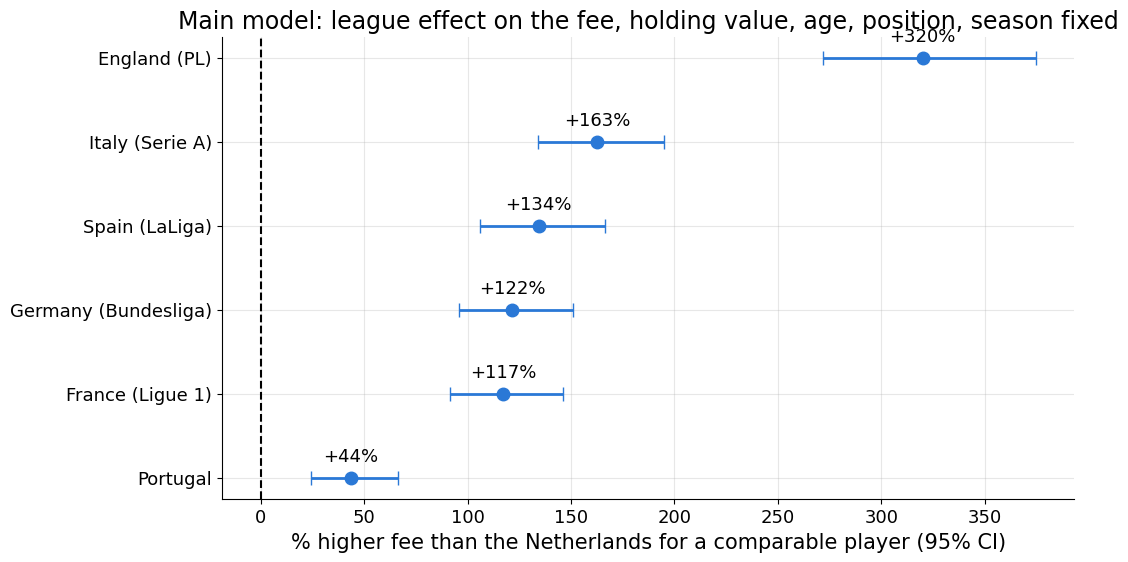

In [14]:
# League % effects (vs Netherlands) with 95% CIs, sorted from largest to smallest
def league_effects(m, ref):
    """League dummies of a fitted model as % effects with 95% CIs (reference league = 0)."""
    ci = m.conf_int()
    rows = []
    for term in m.params.index:
        mm = re.match(r"C\(league_name.*\)\[T\.(.+)\]", term)
        if mm:
            rows.append({"league": mm.group(1), "b": m.params[term], "p": m.pvalues[term],
                         "pct": pct(m.params[term]), "pct_lo": pct(ci.loc[term, 0]), "pct_hi": pct(ci.loc[term, 1])})
    return pd.DataFrame(rows)

lg = league_effects(main, LEAGUE_REF).sort_values("pct")
lg_hc3 = league_effects(main_hc3, LEAGUE_REF).set_index("league")
lg["p_HC3"] = lg["league"].map(lg_hc3["p"])
print(fmt_p(lg.round(3)).to_string(index=False))
save_table(lg, "main_league_effects.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(lg))
ax.errorbar(lg["pct"], y, xerr=[lg["pct"] - lg["pct_lo"], lg["pct_hi"] - lg["pct"]],
            fmt="o", color=COLORS[0], ms=9, capsize=5, lw=2)
for yi, v in zip(y, lg["pct"]):
    ax.text(v, yi + 0.2, f"{v:+.0f}%", ha="center", fontsize=13)
ax.axvline(0, color="black", ls="--", lw=1.5)
ax.set_yticks(y)
ax.set_yticklabels([LEAGUE_LABEL[l] for l in lg["league"]])
ax.set_xlabel("% higher fee than the Netherlands for a comparable player (95% CI)")
ax.set_title("Main model: league effect on the fee, holding value, age, position, season fixed")
save_fig(fig, "fig04_league_effects_main.png")

In [15]:
# The coefficient on log(market value) is an elasticity:
# +1% market value -> +b% fee. If b < 1, fees grow less than proportionally with value.
b_val = main.params["log_val"]
ci_val = main.conf_int().loc["log_val"]
print(f"fee elasticity w.r.t. market value: {b_val:.3f}  (95% CI {ci_val[0]:.3f} to {ci_val[1]:.3f}),"
      f" HC3 SE = {main_hc3.bse['log_val']:.3f}")
print(f"a 10% higher market value -> {((1.10 ** b_val) - 1) * 100:.1f}% higher fee")
print(f"a market value twice as high -> {((2 ** b_val) - 1) * 100:.1f}% higher fee")

fee elasticity w.r.t. market value: 0.523  (95% CI 0.504 to 0.542), HC3 SE = 0.010
a 10% higher market value -> 5.1% higher fee
a market value twice as high -> 43.7% higher fee


**Reading the elasticity.** The coefficient on `log_val` is the % change in the fee for a 1 % change in market value, holding the other variables fixed. A value of 1 would mean fees scale exactly with market values; a value below 1 means that a more valuable player costs more in euros but less **relative to his value**, so the premium (fee/value) falls as market value rises. The exact numbers are printed above and summarised in the Takeaway.

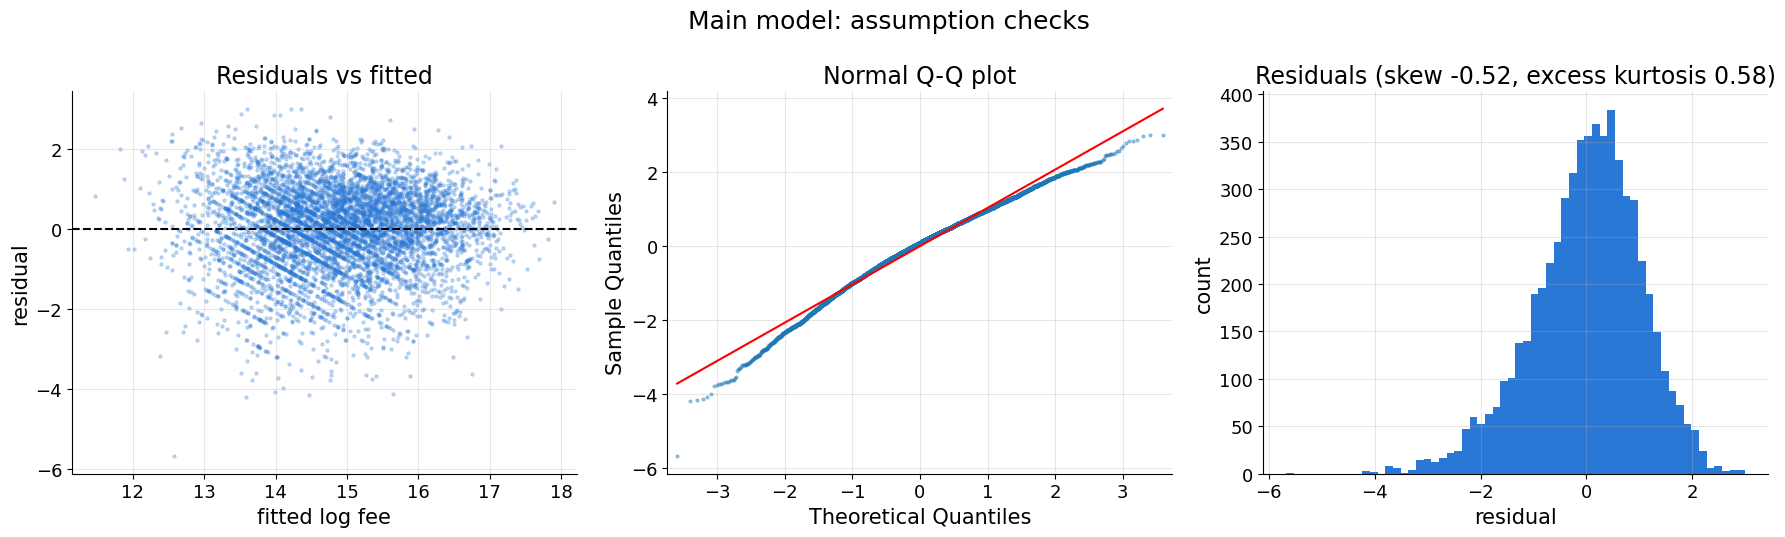

Spearman(|residual|, fitted) = -0.122, p = 1.92e-21
residual sd by fitted-value quartile:
Q1    1.185
Q2    1.032
Q3    0.979
Q4    0.919

transfers: 6,063 | distinct players: 4,179 | distinct buying clubs: 219


In [16]:
# Assumption checks on the residuals (residual = observed log fee - fitted log fee)
resid, fitted = main.resid, main.fittedvalues
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
ax[0].scatter(fitted, resid, s=5, alpha=0.25, color=COLORS[0])
ax[0].axhline(0, color="black", ls="--")
ax[0].set_xlabel("fitted log fee"); ax[0].set_ylabel("residual")
ax[0].set_title("Residuals vs fitted")
sm.qqplot(resid, line="s", ax=ax[1], markersize=2, alpha=0.4)       # points on the line = normal residuals
ax[1].set_title("Normal Q-Q plot")
ax[2].hist(resid, bins=60, color=COLORS[0])
ax[2].set_xlabel("residual"); ax[2].set_ylabel("count")
ax[2].set_title(f"Residuals (skew {stats.skew(resid):.2f}, excess kurtosis {stats.kurtosis(resid):.2f})")
fig.suptitle("Main model: assumption checks", fontsize=18)
fig.tight_layout()
save_fig(fig, "fig05_assumption_checks.png")

# numeric check of constant variance: does the size of the residual change with the fitted value?
rho_h, p_h = stats.spearmanr(fitted, resid.abs())
print(f"Spearman(|residual|, fitted) = {rho_h:.3f}, p = {p_h:.2e}")
print(f"residual sd by fitted-value quartile:")
print(resid.groupby(pd.qcut(fitted, 4, labels=["Q1", "Q2", "Q3", "Q4"]), observed=True).std().round(3).to_string())
# independence: the same player or club can appear many times
print(f"\ntransfers: {len(d):,} | distinct players: {d['player_id'].nunique():,} | distinct buying clubs: {d['team_id'].nunique()}")

**Assumptions of linear regression (from the course): linearity, independence, normality, constant variance.**

* **Linearity:** the residuals-vs-fitted cloud is centred on 0 across the whole range of fitted values, with no curved pattern. The parallel diagonal stripes come from fees being recorded as round amounts (€1M, €2M, …).
* **Independence:** there are 6,063 transfers but only **4,179 distinct players** and **219 buying clubs**. The same player or club appears several times, so the observations are not fully independent and the standard errors may be somewhat too small.
* **Normality:** the histogram is bell-shaped with a longer left tail (**skew −0.52, excess kurtosis 0.58**). The Q-Q plot bends away from the line in both tails. With n = 6,063 the coefficient tests rely mostly on the large sample, not on exact normality.
* **Constant variance:** the residual sd falls from **1.185** (lowest fitted quartile) to **0.919** (highest), and Spearman(|residual|, fitted) = **−0.122, p = 1.9 × 10⁻²¹**. The variance is not constant, which is why HC3 SEs are reported. They are close to the normal SEs (e.g. England 0.062 vs 0.066) and every league, position and age p-value stays below 0.001.

### Takeaway

* Main model: n = **6,063**, **R² = 0.475**.
* For a comparable player, every league pays more than the Netherlands. In order of size: **England +320 % [+272, +375]**, Italy +163 % [+134, +195], Spain +134 % [+106, +166], Germany +122 % [+96, +151], France +117 % [+92, +146] and Portugal +44 % [+24, +66]. All have p < 0.001 with normal and with HC3 SEs.
* England's CI does not overlap with any other league's. The CIs of Spain, Germany and France overlap with each other.
* **Elasticity = 0.523** [0.504, 0.542]. A 10 % higher market value goes with a 5.1 % higher fee, and doubling the value goes with a 43.7 % higher fee.
* Other effects in the same model: positions vs attackers GK −35.0 %, DEF −22.7 %, MID −11.5 %. Age vs ≤21: 22–25 +54.8 %, 26–29 +115.2 %, 30+ +83.8 %. A domestic purchase costs −18.7 %.

### 4c. Absolute overpay: predicted ratio for a standard player
**Question:** for the same standard player (median market value, age 22–25, midfielder, most recent season, bought from abroad), does each league's predicted fee exceed his market value (ratio > 1)?

We use the fitted main model to predict log(fee) for this player in each league; `get_prediction` gives a 95 % confidence interval for the prediction. Since the model is in logs, exp(prediction) is a *typical* (median-type) fee, and dividing it by the market value gives the predicted ratio.

standard player: market value EUR 2,000,000, MID, age 22-25, season 2021, bought abroad

     league  pred_fee_eur  ratio  ratio_lo  ratio_hi  ratio_lo_HC3  ratio_hi_HC3  CI_above_1
    England    4870936.71   2.44      2.13      2.79          2.18          2.72        True
      Italy    3047577.54   1.52      1.34      1.73          1.37          1.70        True
      Spain    2717808.08   1.36      1.18      1.56          1.20          1.53        True
    Germany    2570344.15   1.29      1.12      1.47          1.15          1.44        True
     France    2520195.50   1.26      1.10      1.45          1.12          1.42        True
   Portugal    1667026.57   0.83      0.72      0.97          0.72          0.97       False
Netherlands    1159856.48   0.58      0.50      0.68          0.50          0.67       False


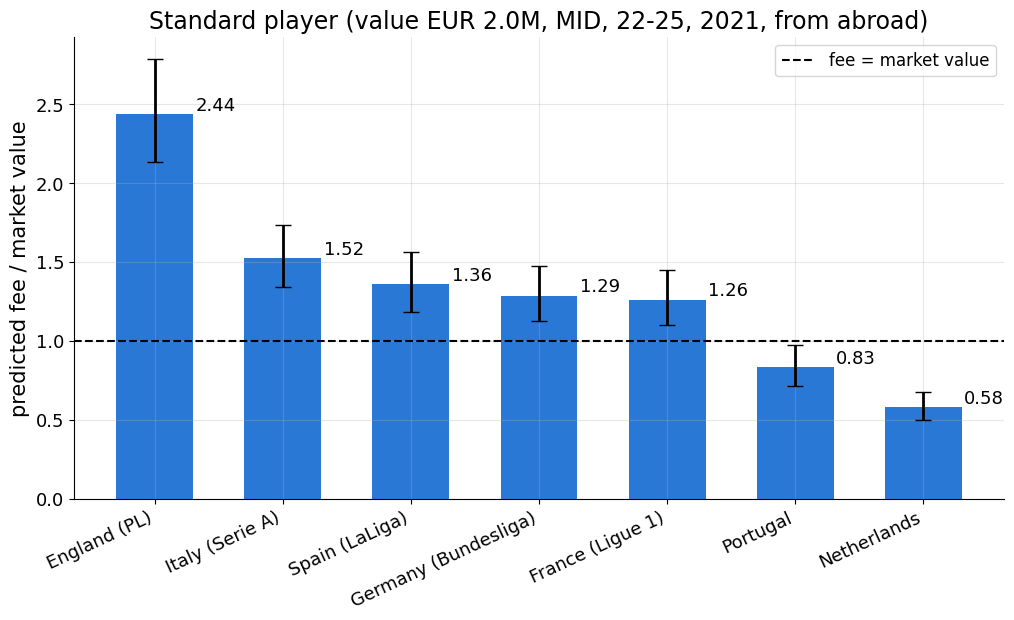

In [17]:
LEAGUES = sorted(d["league_name"].unique())
med_val = d["market_val_amnt"].median()
last_season = d["season"].max()

# one row per league, everything else fixed at the standard player
standard = pd.DataFrame({"league_name": LEAGUES, "log_val": np.log(med_val), "pos_group": "MID",
                         "age_band": "22-25", "season": last_season, "is_domestic": False})

pred = main.get_prediction(standard).summary_frame(alpha=0.05)          # normal CI
pred_r = main_hc3.get_prediction(standard).summary_frame(alpha=0.05)    # HC3 CI
std_player = pd.DataFrame({
    "league": LEAGUES,
    "pred_fee_eur": np.exp(pred["mean"].values),
    "ratio": np.exp(pred["mean"].values - np.log(med_val)),
    "ratio_lo": np.exp(pred["mean_ci_lower"].values - np.log(med_val)),
    "ratio_hi": np.exp(pred["mean_ci_upper"].values - np.log(med_val)),
    "ratio_lo_HC3": np.exp(pred_r["mean_ci_lower"].values - np.log(med_val)),
    "ratio_hi_HC3": np.exp(pred_r["mean_ci_upper"].values - np.log(med_val)),
}).sort_values("ratio", ascending=False)
std_player["CI_above_1"] = std_player["ratio_lo"] > 1
print(f"standard player: market value EUR {med_val:,.0f}, MID, age 22-25, season {last_season}, bought abroad\n")
print(std_player.round(2).to_string(index=False))
save_table(std_player, "standard_player_ratio.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(std_player))
ax.bar(x, std_player["ratio"], color=COLORS[0], width=0.6,
       yerr=[std_player["ratio"] - std_player["ratio_lo"], std_player["ratio_hi"] - std_player["ratio"]],
       capsize=6, error_kw=dict(lw=2))
ax.axhline(1, color="black", ls="--", lw=1.5, label="fee = market value")
for xi, r in zip(x, std_player["ratio"]):
    ax.text(xi + 0.32, r, f"{r:.2f}", va="bottom", fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels([LEAGUE_LABEL[l] for l in std_player["league"]], rotation=25, ha="right")
ax.set_ylabel("predicted fee / market value")
ax.set_title(f"Standard player (value EUR {med_val/1e6:.1f}M, MID, 22-25, {last_season}, from abroad)")
ax.legend(loc="upper right")
save_fig(fig, "fig06_standard_player_ratio.png")

In [18]:
# Sanity check against the expected values (log scale, vs Netherlands)
expected = {"England": 1.4, "Italy": 0.9, "Portugal": 0.4}
for lg_name, exp_b in expected.items():
    b = main.params[f"C(league_name, Treatment('Netherlands'))[T.{lg_name}]"]
    print(f"{lg_name:9s} b = {b:.3f}  (expected about {exp_b})")
print(f"elasticity = {main.params['log_val']:.3f} (expected about 0.54)")
print(f"n = {int(main.nobs):,} (expected about 6,060)")

England   b = 1.435  (expected about 1.4)
Italy     b = 0.966  (expected about 0.9)
Portugal  b = 0.363  (expected about 0.4)
elasticity = 0.523 (expected about 0.54)
n = 6,063 (expected about 6,060)


### Takeaway

* The standard player has a market value of €2.0M, is a midfielder aged 22–25, moves in 2021 and is bought from abroad. His predicted fee/value ratio is **England 2.44 [2.13, 2.79]**, Italy 1.52 [1.34, 1.73], Spain 1.36 [1.18, 1.56], Germany 1.29 [1.12, 1.47], France 1.26 [1.10, 1.45], **Portugal 0.83 [0.72, 0.97]** and **Netherlands 0.58 [0.50, 0.68]**.
* Five leagues have the whole 95 % CI above 1 (absolute overpay for this player). For Portugal and the Netherlands the whole CI is below 1. The HC3 intervals lead to the same classification.
* Sanity check: England b = 1.435, Italy 0.966, Portugal 0.363, n = 6,063, all as expected. The elasticity is 0.523 instead of about 0.54, but 0.54 lies inside its 95 % CI (0.504–0.542).

## 5. BRANCH 1: role of age
**Question:** does the premium depend on the player's age, what shape does that relation have, and does the league ranking hold within every age group?

          size   mean  median
age_band                     
<=21      1933 -0.092   0.000
22-25     2667  0.414   0.288
26-29     1192  0.905   0.875
30+        271  0.894   0.916

ANOVA premium ~ age band: F = 154.18, p = 2.70e-96


group1 group2  meandiff  p-adj   lower   upper  reject
 22-25  26-29    0.4909 0.0000  0.3707  0.6110    True
 22-25    30+    0.4797 0.0000  0.2599  0.6996    True
 22-25   <=21   -0.5058 0.0000 -0.6088 -0.4028    True
 26-29    30+   -0.0111 0.9993 -0.2431  0.2209   False
 26-29   <=21   -0.9966 0.0000 -1.1236 -0.8696    True
   30+   <=21   -0.9855 0.0000 -1.2092 -0.7619    True


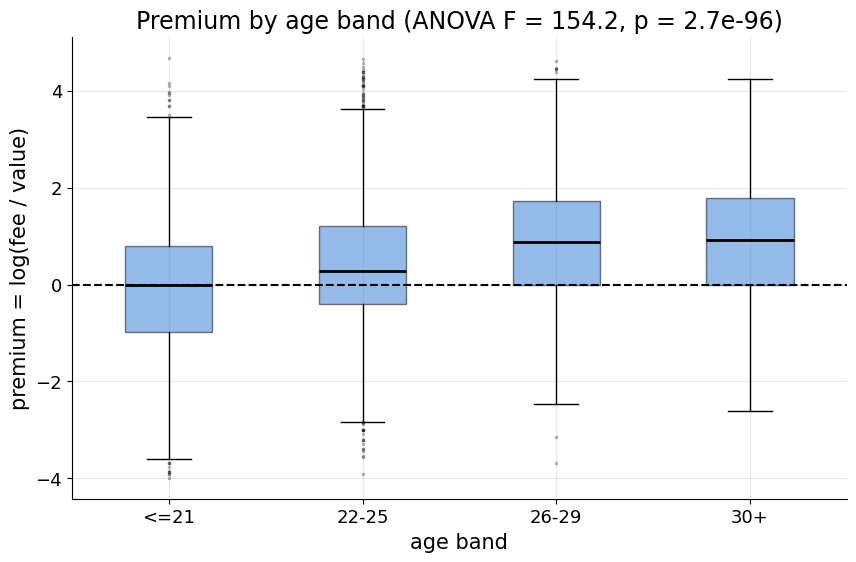


main model, age effects on the fee (vs <=21):
          term     pct  pct_lo  pct_hi       p   p_HC3
age_band=22-25  54.760  45.551  64.551 0.0e+00 0.0e+00
age_band=26-29 115.201  98.968 132.758 0.0e+00 0.0e+00
  age_band=30+  83.778  60.041 111.037 0.0e+00 0.0e+00


In [19]:
# Direct effect: ANOVA + Tukey on the premium across age bands
print(d.groupby("age_band")["premium"].agg(["size", "mean", "median"]).reindex(AGE_ORDER).round(3).to_string())
anova_age = stats.f_oneway(*[d.loc[d["age_band"] == a, "premium"] for a in AGE_ORDER])
print(f"\nANOVA premium ~ age band: F = {anova_age.statistic:.2f}, p = {anova_age.pvalue:.2e}")
tk_age = tukey_df(pairwise_tukeyhsd(d["premium"], d["age_band"], alpha=0.05))
print(tk_age.to_string(index=False))
save_table(tk_age, "tukey_age.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot([d.loc[d["age_band"] == a, "premium"] for a in AGE_ORDER], patch_artist=True,
           boxprops=dict(facecolor=COLORS[0], alpha=0.5), medianprops=dict(color="black", lw=2),
           flierprops=dict(marker=".", markersize=3, alpha=0.3))
ax.axhline(0, color="black", ls="--", lw=1.5)
ax.set_xticks(range(1, 5)); ax.set_xticklabels(AGE_ORDER)
ax.set_xlabel("age band"); ax.set_ylabel("premium = log(fee / value)")
ax.set_title(f"Premium by age band (ANOVA F = {anova_age.statistic:.1f}, p = {anova_age.pvalue:.1e})")
save_fig(fig, "fig07_premium_by_age_box.png")

# controlled age effects from the main model (vs <=21)
age_eff = main_coefs[main_coefs["term"].str.startswith("age_band=")][["term", "pct", "pct_lo", "pct_hi", "p", "p_HC3"]]
print("\nmain model, age effects on the fee (vs <=21):")
print(fmt_p(age_eff.round(3)).to_string(index=False))

b1 (age_c) = 0.1007 (p = 1.03e-103, HC3 p = 2.01e-94)
b2 (age_c2) = -0.0092 (p = 3.16e-22, HC3 p = 2.26e-20)
R^2 quadratic = 0.483  vs  R^2 age bands = 0.475
peak age = 23.32 - (0.1007) / (2 * -0.0092) = 28.8 years  (maximum because b2 < 0)


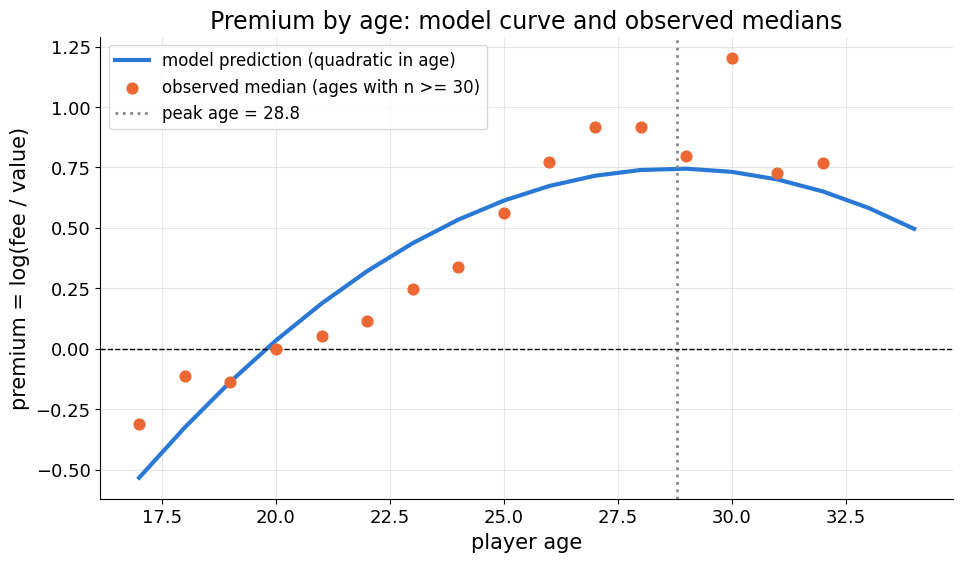

In [20]:
# Shape: replace the age bands by a curve b1*age_c + b2*age_c^2 (age_c = age - mean age)
QUAD_FORMULA = MAIN_FORMULA.replace("C(age_band, Treatment('<=21'))", "age_c + age_c2")
quad = smf.ols(QUAD_FORMULA, data=d).fit()
quad_hc3 = smf.ols(QUAD_FORMULA, data=d).fit(cov_type="HC3")
b1, b2 = quad.params["age_c"], quad.params["age_c2"]
peak_age = MEAN_AGE - b1 / (2 * b2)           # where the slope b1 + 2*b2*age_c equals zero
print(f"b1 (age_c) = {b1:.4f} (p = {quad.pvalues['age_c']:.2e}, HC3 p = {quad_hc3.pvalues['age_c']:.2e})")
print(f"b2 (age_c2) = {b2:.4f} (p = {quad.pvalues['age_c2']:.2e}, HC3 p = {quad_hc3.pvalues['age_c2']:.2e})")
print(f"R^2 quadratic = {quad.rsquared:.3f}  vs  R^2 age bands = {main.rsquared:.3f}")
print(f"peak age = {MEAN_AGE:.2f} - ({b1:.4f}) / (2 * {b2:.4f}) = {peak_age:.1f} years"
      f"  ({'maximum' if b2 < 0 else 'minimum'} because b2 {'<' if b2 < 0 else '>'} 0)")

# Predicted premium at each age: give EVERY transfer the same age, predict, and average
ages = np.arange(17, 35)          # ages with enough data (few transfers above 34)
curve = []
for a in ages:
    tmp = d.copy()
    tmp["age_c"] = a - MEAN_AGE
    tmp["age_c2"] = tmp["age_c"] ** 2
    curve.append((quad.predict(tmp) - tmp["log_val"]).mean())    # predicted log fee - log value = predicted premium

# binned medians of the observed premium (single years with at least 30 transfers)
binned = d.groupby(d["player_age"].astype(int))["premium"].agg(["median", "size"])
binned = binned[binned["size"] >= 30]

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(ages, curve, color=COLORS[0], lw=3, label="model prediction (quadratic in age)")
ax.scatter(binned.index, binned["median"], color=COLORS[1], s=60, zorder=3, label="observed median (ages with n >= 30)")
ax.axvline(peak_age, color=GREY, ls=":", lw=2, label=f"peak age = {peak_age:.1f}")
ax.axhline(0, color="black", ls="--", lw=1)
ax.set_xlabel("player age"); ax.set_ylabel("premium = log(fee / value)")
ax.set_title("Premium by age: model curve and observed medians")
ax.legend()
save_fig(fig, "fig08_age_curve.png")

subgroup           <=21       22-25         26+
league                                         
England       47% [330]  111% [510]   72% [291]
France        21% [269]  -13% [374]  -12% [197]
Italy         24% [551]   13% [624]   11% [391]
Netherlands  -44% [165]  -62% [172]   -54% [52]
Portugal     -27% [116]  -38% [211]   -34% [75]
Spain         34% [165]    3% [349]  -11% [293]
format: % effect vs Germany [n transfers of that league in the subgroup]; * = n < 30

95% CI entirely above 0 (+), entirely below 0 (-), or containing 0 (0):
subgroup    <=21 22-25 26+
league                    
England        +     +   +
France         +     0   0
Italy          +     0   0
Netherlands    -     -   -
Portugal       -     -   -
Spain          +     0   0


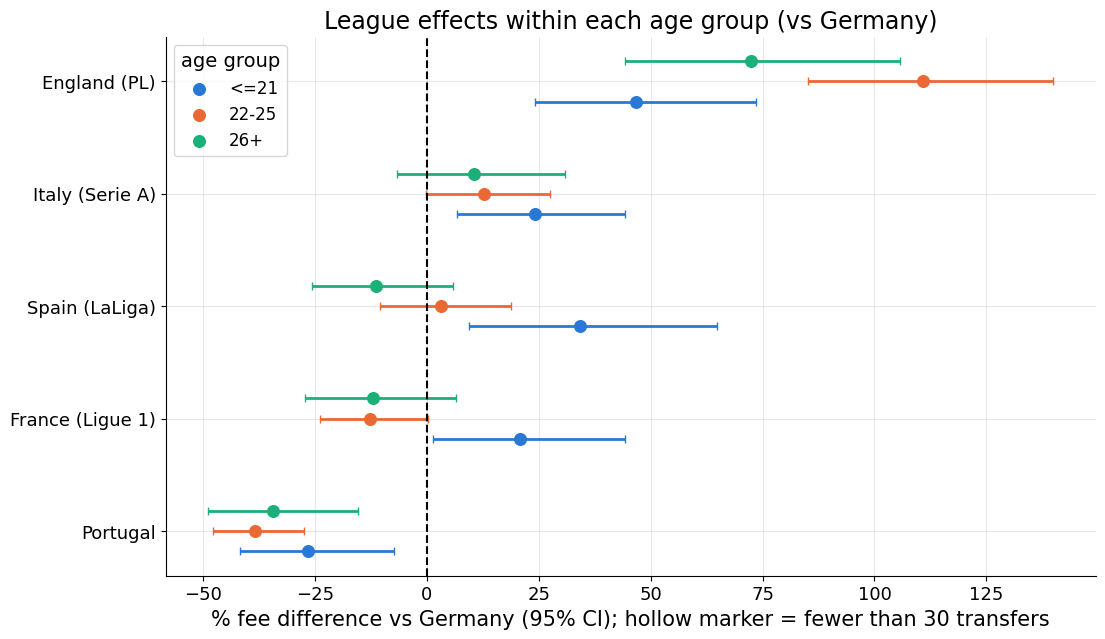

In [21]:
# Consistency: the same league comparison inside each subgroup (reference league = Germany)
# age is controlled with the 3 broad bands (age_band3) because the 30+ band is too small inside subgroups
SUB_FORMULA = ("log_fee ~ C(league_name, Treatment('Germany')) + log_val + C(pos_group) + C(age_band3)"
               " + C(season) + is_domestic")

def subgroup_league_effects(data, group_col, groups):
    """Fit the subgroup model inside each group and collect league % effects vs Germany."""
    out = []
    for g in groups:
        sub = data[data[group_col] == g]
        formula = SUB_FORMULA
        if group_col == "pos_group":              # position is constant inside a position group
            formula = formula.replace(" + C(pos_group)", "")
        if group_col == "age_band3":              # age is constant inside an age group
            formula = formula.replace(" + C(age_band3)", "")
        m = smf.ols(formula, data=sub).fit()
        eff = league_effects(m, "Germany").set_index("league").reindex([l for l in LEAGUES if l != "Germany"])
        eff["n_league"] = sub["league_name"].value_counts().reindex(eff.index).fillna(0).astype(int)
        eff["flag_n_lt_30"] = eff["n_league"] < 30        # too few transfers: estimate is unreliable
        eff["subgroup"] = g
        eff["n_subgroup"] = len(sub)
        eff["R2"] = m.rsquared
        out.append(eff.reset_index())
    return pd.concat(out, ignore_index=True)

def plot_subgroups(tab, groups, title, fname, legend_title):
    """Grouped coefficient plot: one row per league, one coloured point per subgroup; hollow = n < 30."""
    leagues = [l for l in lg["league"] if l != "Germany"]     # same league order as the main plot
    fig, ax = plt.subplots(figsize=(12, 7))
    k = len(groups)
    for i, g in enumerate(groups):
        t = tab[tab["subgroup"] == g].set_index("league").reindex(leagues)
        y = np.arange(len(leagues)) + (i - (k - 1) / 2) * 0.18
        ax.errorbar(t["pct"], y, xerr=[t["pct"] - t["pct_lo"], t["pct_hi"] - t["pct"]], fmt="none",
                    ecolor=COLORS[i], lw=2, capsize=3)
        ok = ~t["flag_n_lt_30"].values
        ax.scatter(t["pct"][ok], y[ok], color=COLORS[i], s=70, zorder=3, label=str(g))
        ax.scatter(t["pct"][~ok], y[~ok], facecolor="white", edgecolor=COLORS[i], s=70, lw=2, zorder=3)
    ax.axvline(0, color="black", ls="--", lw=1.5)
    ax.set_yticks(np.arange(len(leagues)))
    ax.set_yticklabels([LEAGUE_LABEL[l] for l in leagues])
    ax.set_xlabel("% fee difference vs Germany (95% CI); hollow marker = fewer than 30 transfers")
    ax.set_title(title)
    ax.legend(title=legend_title, loc="best")
    save_fig(fig, fname)

def show_subgroups(tab, groups):
    """Print a compact league x subgroup table of % effects; '*' marks cells with n < 30."""
    cell = tab["pct"].round(0).astype("Int64").astype(str) + "% [" + tab["n_league"].astype(str) + "]" \
           + np.where(tab["flag_n_lt_30"], "*", "")
    print(tab.assign(cell=cell).pivot(index="league", columns="subgroup", values="cell")[groups].to_string())
    print("format: % effect vs Germany [n transfers of that league in the subgroup]; * = n < 30")
    ci_excl = np.where(tab["pct_lo"] > 0, "+", np.where(tab["pct_hi"] < 0, "-", "0"))
    print("\n95% CI entirely above 0 (+), entirely below 0 (-), or containing 0 (0):")
    print(tab.assign(ci=ci_excl).pivot(index="league", columns="subgroup", values="ci")[groups].to_string())

sub_age = subgroup_league_effects(d, "age_band3", AGE3_ORDER)
show_subgroups(sub_age, AGE3_ORDER)
save_table(sub_age, "subgroup_age_league_effects.csv", index=False)
plot_subgroups(sub_age, AGE3_ORDER, "League effects within each age group (vs Germany)",
               "fig09_subgroup_age.png", "age group")

**Caution on interpreting age.** The premium compares the fee with the *Transfermarkt market value*. If Transfermarkt systematically marks down older players' values faster than clubs lower what they are willing to pay, older players will show a higher premium even though no club is "overpaying". The age effect therefore may partly measure how the market value is built, not club behaviour.

### Takeaway

* Mean premium by age band: ≤21 −0.092, 22–25 0.414, 26–29 0.905, 30+ 0.894. **ANOVA F = 154.18, p = 2.7 × 10⁻⁹⁶.** Tukey: every pair differs except 26–29 vs 30+ (p = 0.999).
* Main model vs ≤21: +54.8 % (22–25), +115.2 % (26–29), +83.8 % (30+).
* Quadratic fit: b1 = 0.1007, b2 = −0.0092, both p < 10⁻²¹. **Peak age = 28.8 years.** R² rises from 0.475 to 0.483.
* Within each age group (vs Germany):
  * **England is positive in all three**: +47 %, +111 %, +72 %, all CIs above 0.
  * **The Netherlands (−44 to −62 %) and Portugal (−27 to −38 %) are negative in all three**, all CIs below 0.
  * Italy is +24 %, +13 %, +11 %, but only the ≤21 CI excludes 0.
  * Spain and France are positive only for ≤21 (+34 %, +21 %). In the older groups their CIs contain 0.
* No league × age cell has n < 30.

## 6. BRANCH 2: role of position
**Question:** does the premium depend on position, why do raw and controlled position effects differ, does the league ranking hold within each position, and how much does position explain compared with age?

           size   mean  median
pos_group                     
GK          396  0.376   0.357
DEF        1849  0.281   0.223
MID        1755  0.339   0.262
ATT        2063  0.478   0.434

ANOVA premium ~ position: F = 7.02, p = 1.04e-04


group1 group2  meandiff  p-adj   lower   upper  reject
   ATT    DEF   -0.1976 0.0001 -0.3119 -0.0832    True
   ATT     GK   -0.1027 0.5328 -0.2986  0.0932   False
   ATT    MID   -0.1396 0.0107 -0.2555 -0.0236    True
   DEF     GK    0.0949 0.6059 -0.1029  0.2926   False
   DEF    MID    0.0580 0.5931 -0.0610  0.1770   False
    GK    MID   -0.0368 0.9643 -0.2355  0.1618   False


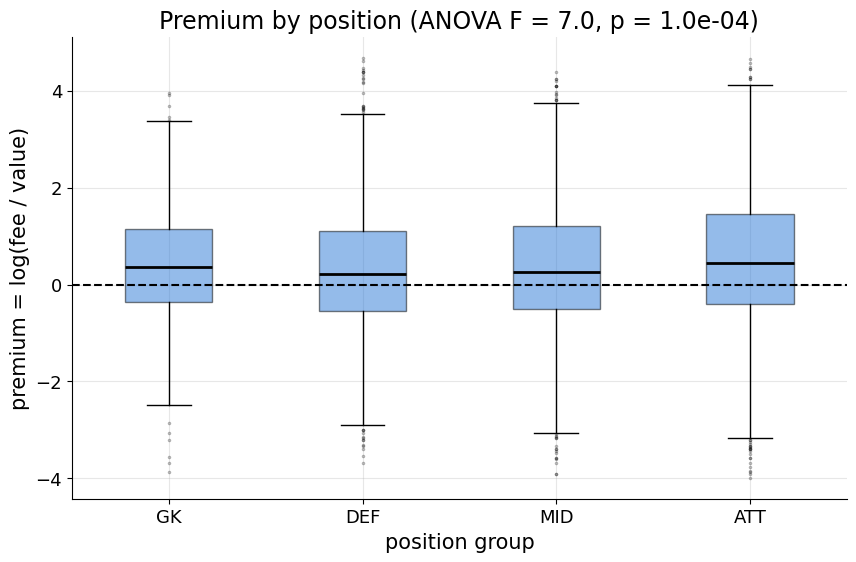

In [22]:
# Direct effect: ANOVA + Tukey on premium across positions
print(d.groupby("pos_group")["premium"].agg(["size", "mean", "median"]).reindex(POS_ORDER).round(3).to_string())
anova_pos = stats.f_oneway(*[d.loc[d["pos_group"] == p, "premium"] for p in POS_ORDER])
print(f"\nANOVA premium ~ position: F = {anova_pos.statistic:.2f}, p = {anova_pos.pvalue:.2e}")
tk_pos = tukey_df(pairwise_tukeyhsd(d["premium"], d["pos_group"], alpha=0.05))
print(tk_pos.to_string(index=False))
save_table(tk_pos, "tukey_position.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot([d.loc[d["pos_group"] == p, "premium"] for p in POS_ORDER], patch_artist=True,
           boxprops=dict(facecolor=COLORS[0], alpha=0.5), medianprops=dict(color="black", lw=2),
           flierprops=dict(marker=".", markersize=3, alpha=0.3))
ax.axhline(0, color="black", ls="--", lw=1.5)
ax.set_xticks(range(1, 5)); ax.set_xticklabels(POS_ORDER)
ax.set_xlabel("position group"); ax.set_ylabel("premium = log(fee / value)")
ax.set_title(f"Premium by position (ANOVA F = {anova_pos.statistic:.1f}, p = {anova_pos.pvalue:.1e})")
save_fig(fig, "fig10_premium_by_position_box.png")

In [23]:
# Raw vs controlled: raw median premium next to the controlled % effect from the main model (ATT = reference)
pos_eff = main_coefs[main_coefs["term"].str.startswith("pos_group=")].copy()
pos_eff["pos_group"] = pos_eff["term"].str.replace("pos_group=", "")
pos_eff = pos_eff.set_index("pos_group")[["pct", "pct_lo", "pct_hi", "p", "p_HC3"]]
pos_eff.loc["ATT"] = [0.0, np.nan, np.nan, np.nan, np.nan]          # reference category

raw_vs_ctrl = pd.DataFrame({
    "n": d["pos_group"].value_counts(),
    "raw_median_premium": d.groupby("pos_group")["premium"].median(),
    "raw_median_ratio": d.groupby("pos_group")["ratio"].median(),
    "mean_age": d.groupby("pos_group")["player_age"].mean(),
}).join(pos_eff.rename(columns={"pct": "controlled_pct_vs_ATT"})).reindex(POS_ORDER)
print(fmt_p(raw_vs_ctrl.round(3)).to_string())
save_table(raw_vs_ctrl, "position_raw_vs_controlled.csv")

# Why goalkeepers can look different raw vs controlled: their age mix
age_pos = pd.crosstab(d["pos_group"], d["age_band"], normalize="index").reindex(index=POS_ORDER, columns=AGE_ORDER) * 100
print("\nage mix within each position (% of rows):")
print(age_pos.round(1).to_string())
save_table(age_pos, "crosstab_position_age_pct.csv")

              n  raw_median_premium  raw_median_ratio  mean_age  controlled_pct_vs_ATT  pct_lo  pct_hi        p    p_HC3
pos_group                                                                                                               
GK          396               0.357             1.429    24.942                -35.030 -41.972 -27.257  0.0e+00  0.0e+00
DEF        1849               0.223             1.250    23.335                -22.722 -27.609 -17.505  0.0e+00  0.0e+00
MID        1755               0.262             1.300    23.125                -11.529 -17.191  -5.479  0.0e+00  0.0e+00
ATT        2063               0.434             1.544    23.161                  0.000     NaN     NaN                  

age mix within each position (% of rows):
age_band   <=21  22-25  26-29   30+
pos_group                          
GK         21.0   36.6   28.3  14.1
DEF        30.6   45.6   19.0   4.7
MID        34.4   43.4   18.6   3.7
ATT        33.0   44.4   19.5   3.1


subgroup             GK         DEF         MID         ATT
league                                                     
England       155% [85]   68% [357]   90% [303]   99% [386]
France         25% [44]  -12% [244]   -5% [236]    5% [316]
Italy         90% [100]    8% [517]   15% [493]   21% [456]
Netherlands  -28% [23]*  -51% [101]  -59% [114]  -57% [151]
Portugal      -2% [23]*  -32% [115]  -34% [132]  -42% [132]
Spain          43% [59]   -6% [242]    9% [206]    7% [300]
format: % effect vs Germany [n transfers of that league in the subgroup]; * = n < 30

95% CI entirely above 0 (+), entirely below 0 (-), or containing 0 (0):
subgroup    GK DEF MID ATT
league                    
England      +   +   +   +
France       0   0   0   0
Italy        +   0   0   +
Netherlands  0   -   -   -
Portugal     0   -   -   -
Spain        0   0   0   0


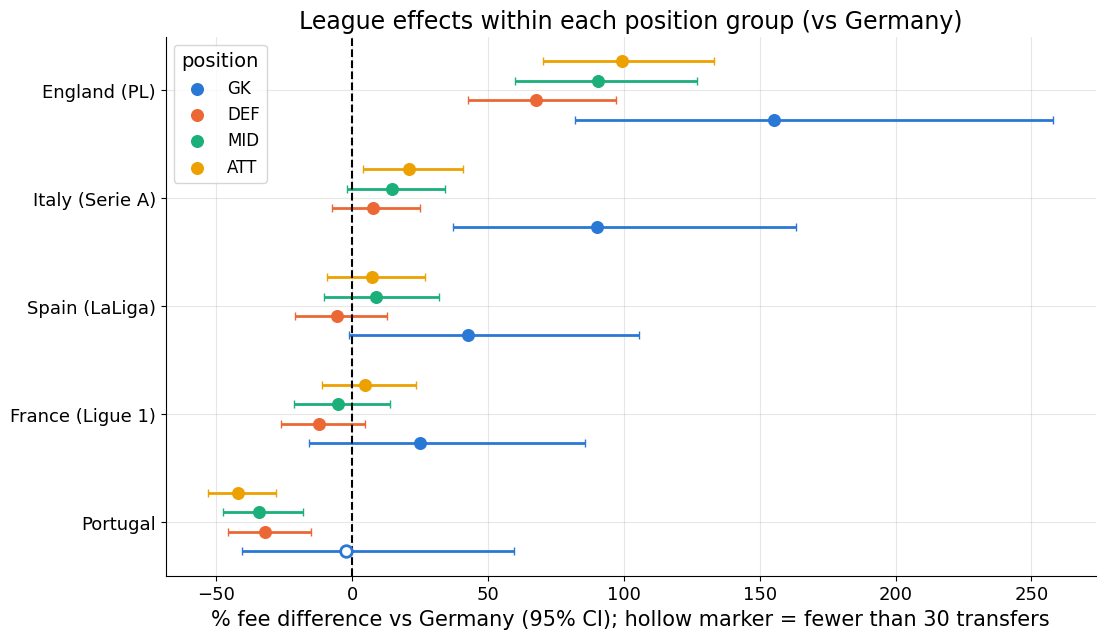

In [24]:
# Consistency: league effects within each position group (Germany = reference)
sub_pos = subgroup_league_effects(d, "pos_group", POS_ORDER)
show_subgroups(sub_pos, POS_ORDER)
save_table(sub_pos, "subgroup_position_league_effects.csv", index=False)
plot_subgroups(sub_pos, POS_ORDER, "League effects within each position group (vs Germany)",
               "fig11_subgroup_position.png", "position")

                                      R2  delta_R2
(a) league + season + log_val     0.4299       NaN
(b) (a) + position                0.4367    0.0067
(c) (b) + age band                0.4701    0.0334
(d) (a) + age band [order check]  0.4620    0.0320


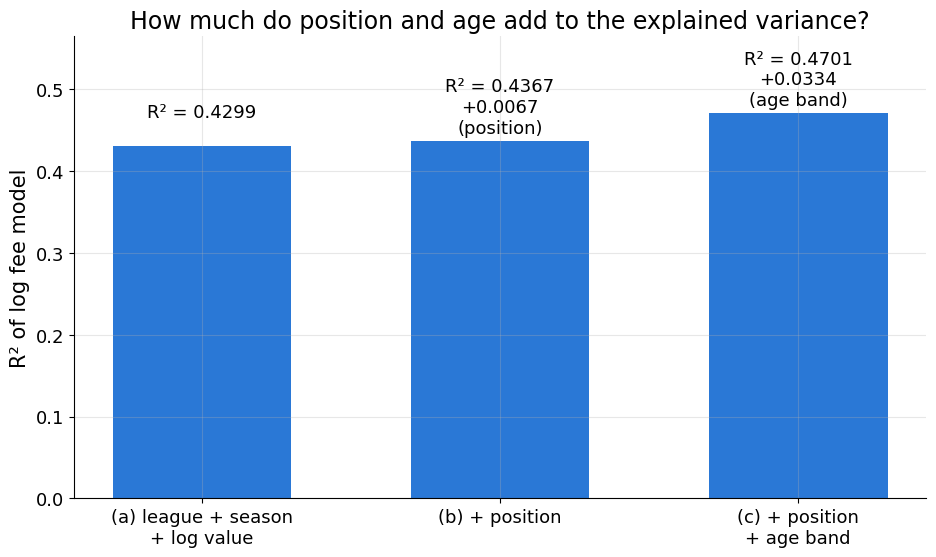

In [25]:
# Contribution to R^2: add position, then age, to a base model and see how much R^2 rises
r2_specs = {
    "(a) league + season + log_val": "log_fee ~ C(league_name) + C(season) + log_val",
    "(b) (a) + position": "log_fee ~ C(league_name) + C(season) + log_val + C(pos_group)",
    "(c) (b) + age band": "log_fee ~ C(league_name) + C(season) + log_val + C(pos_group) + C(age_band)",
    "(d) (a) + age band [order check]": "log_fee ~ C(league_name) + C(season) + log_val + C(age_band)",
}
r2 = pd.DataFrame({"R2": {k: smf.ols(f, data=d).fit().rsquared for k, f in r2_specs.items()}})
r2["delta_R2"] = [np.nan,
                  r2["R2"].iloc[1] - r2["R2"].iloc[0],     # gain from position
                  r2["R2"].iloc[2] - r2["R2"].iloc[1],     # gain from age, given position
                  r2["R2"].iloc[3] - r2["R2"].iloc[0]]     # gain from age alone
print(r2.round(4).to_string())
save_table(r2, "r2_contribution.csv")
dR2_pos, dR2_age = r2["delta_R2"].iloc[1], r2["delta_R2"].iloc[2]

fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(range(3), r2["R2"].iloc[:3], color=COLORS[0], width=0.6)
labels = ["", f"+{dR2_pos:.4f}\n(position)", f"+{dR2_age:.4f}\n(age band)"]
for i in range(3):
    ax.text(i, r2["R2"].iloc[i] + 0.005, f"R² = {r2['R2'].iloc[i]:.4f}\n{labels[i]}", ha="center", va="bottom", fontsize=13)
ax.set_xticks(range(3)); ax.set_xticklabels(["(a) league + season\n+ log value", "(b) + position", "(c) + position\n+ age band"])
ax.set_ylim(0, r2["R2"].max() * 1.2)
ax.set_ylabel("R² of log fee model")
ax.set_title("How much do position and age add to the explained variance?")
save_fig(fig, "fig12_r2_contribution.png")

### Takeaway

* Mean premium by position: GK 0.376, DEF 0.281, MID 0.339, ATT 0.478. **ANOVA F = 7.02, p = 1.0 × 10⁻⁴.** Tukey: only ATT–DEF and ATT–MID differ.
* **Goalkeepers:** their raw median premium (0.357) is second only to attackers (0.434). In the main model, however, GKs have the **most negative effect, −35.0 % [−42.0, −27.3]**, ahead of DEF −22.7 % and MID −11.5 %.
* The age crosstab shows why the two can differ: **42.4 % of GKs are 26+** (28.3 % + 14.1 %), against 22–24 % in the other groups, and their mean age is 24.9 vs 23.1–23.3. Section 5 showed older players carry higher premiums.
* Within each position (vs Germany, holding the age band fixed):
  * **England is positive in all four** (GK +155 %, DEF +68 %, MID +90 %, ATT +99 %), all CIs above 0.
  * The Netherlands and Portugal are negative for DEF, MID and ATT, with CIs below 0. Their GK cells (n = 23 each) are flagged as n < 30.
  * Italy is positive in all four (CI above 0 for GK and ATT). Spain is positive for GK, MID and ATT (+43 %, +9 %, +7 %) and −6 % for DEF, and its CI contains 0 in all four.
  * France's CI contains 0 in every position.
* R²: base model 0.4299. **Adding position: +0.0067. Adding age band after position: +0.0334.** Age alone added to the base gives +0.0320. In one number each, age explains about five times more of the fee variance than position.

## 6b. BRANCH: deal size
**Question:** does the premium depend on how valuable the player is, and does the league ranking hold for cheap and expensive players alike?

In [26]:
# Elasticity from the main model and what it implies for cheap vs expensive players
print(f"fee elasticity (main model): {b_val:.3f}")
print(f"premium = log fee - log value, so 1 extra log point of value changes the premium by {b_val - 1:+.3f}")

# predictions from the fitted model: the standard player of section 4c, placed at the median value
# of each quartile; we predict for every league and report the average, min and max ratio
tier_med = d.groupby("value_tier")["market_val_amnt"].median().reindex(TIER_ORDER)
rows = []
for tier, v in tier_med.items():
    tmp = standard.copy()
    tmp["log_val"] = np.log(v)
    ratio_t = np.exp(main.predict(tmp) - np.log(v))       # predicted ratio for each league at this value
    rows.append({"value_tier": tier, "median_value_eur": v, "pred_ratio_mean_over_leagues": ratio_t.mean(),
                 "pred_ratio_min": ratio_t.min(), "pred_ratio_max": ratio_t.max()})
tier_pred = pd.DataFrame(rows)
print("\npredicted fee/value ratio of the standard player at each tier's median value:")
print(tier_pred.round(2).to_string(index=False))
save_table(tier_pred, "deal_size_predicted_ratio.csv", index=False)

fee elasticity (main model): 0.523
premium = log fee - log value, so 1 extra log point of value changes the premium by -0.477

predicted fee/value ratio of the standard player at each tier's median value:
value_tier  median_value_eur  pred_ratio_mean_over_leagues  pred_ratio_min  pred_ratio_max
        Q1          300000.0                          3.28            1.43            6.02
        Q2         1200000.0                          1.69            0.74            3.11
        Q3         4000000.0                          0.95            0.42            1.75
        Q4        16000000.0                          0.49            0.22            0.90


            size   mean  median
value_tier                     
Q1          1649  1.368   1.427
Q2          1517  0.578   0.642
Q3          1445  0.007   0.082
Q4          1452 -0.616  -0.405

ANOVA premium ~ value tier: F = 793.13, p = 0.00e+00


group1 group2  meandiff  p-adj   lower   upper  reject
    Q1     Q2   -0.7898    0.0 -0.8977 -0.6820    True
    Q1     Q3   -1.3608    0.0 -1.4701 -1.2516    True
    Q1     Q4   -1.9842    0.0 -2.0932 -1.8751    True
    Q2     Q3   -0.5710    0.0 -0.6824 -0.4596    True
    Q2     Q4   -1.1943    0.0 -1.3056 -1.0830    True
    Q3     Q4   -0.6233    0.0 -0.7360 -0.5107    True


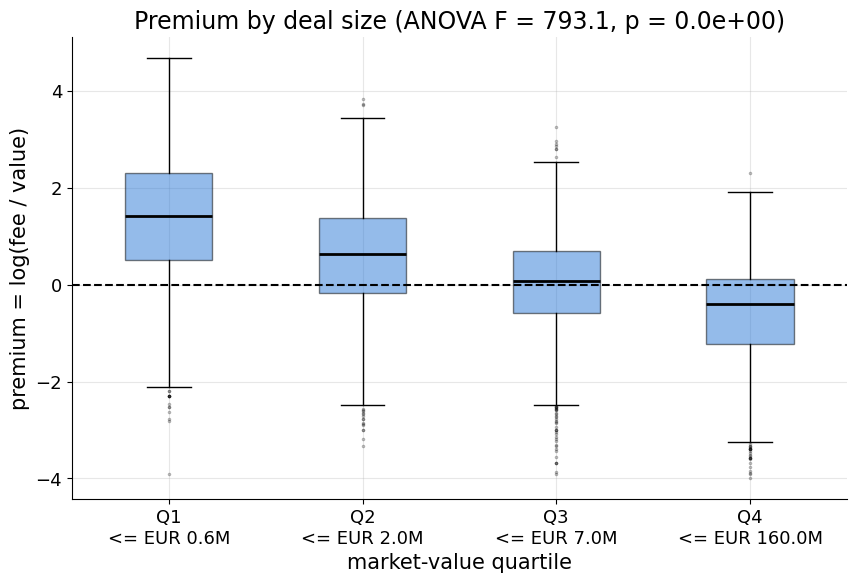

subgroup             Q1          Q2         Q3          Q4
league                                                    
England      108% [188]   99% [261]  97% [282]   54% [400]
France        25% [207]  -15% [200]   5% [238]  -13% [195]
Italy         38% [567]   18% [372]  32% [330]   -7% [297]
Netherlands  -48% [155]  -55% [105]  -50% [79]   -49% [50]
Portugal     -31% [139]  -30% [106]  -33% [97]   -18% [60]
Spain         27% [162]   -7% [226]  12% [191]    7% [228]
format: % effect vs Germany [n transfers of that league in the subgroup]; * = n < 30

95% CI entirely above 0 (+), entirely below 0 (-), or containing 0 (0):
subgroup    Q1 Q2 Q3 Q4
league                 
England      +  +  +  +
France       +  0  0  0
Italy        +  +  +  0
Netherlands  -  -  -  -
Portugal     -  -  -  0
Spain        +  0  0  0


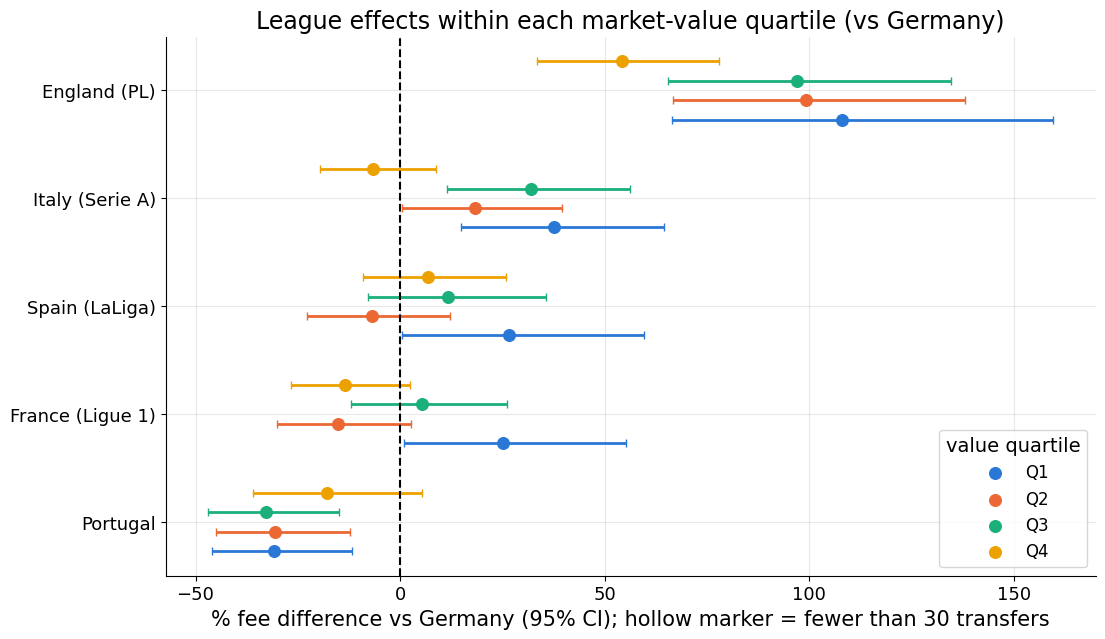

In [27]:
# ANOVA + Tukey on premium across market-value quartiles
print(d.groupby("value_tier")["premium"].agg(["size", "mean", "median"]).reindex(TIER_ORDER).round(3).to_string())
anova_tier = stats.f_oneway(*[d.loc[d["value_tier"] == t, "premium"] for t in TIER_ORDER])
print(f"\nANOVA premium ~ value tier: F = {anova_tier.statistic:.2f}, p = {anova_tier.pvalue:.2e}")
tk_tier = tukey_df(pairwise_tukeyhsd(d["premium"], d["value_tier"], alpha=0.05))
print(tk_tier.to_string(index=False))
save_table(tk_tier, "tukey_value_tier.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot([d.loc[d["value_tier"] == t, "premium"] for t in TIER_ORDER], patch_artist=True,
           boxprops=dict(facecolor=COLORS[0], alpha=0.5), medianprops=dict(color="black", lw=2),
           flierprops=dict(marker=".", markersize=3, alpha=0.3))
ax.axhline(0, color="black", ls="--", lw=1.5)
ax.set_xticks(range(1, 5))
ax.set_xticklabels([f"{t}\n<= EUR {e/1e6:.1f}M" for t, e in zip(TIER_ORDER, tier_edges[1:])])
ax.set_xlabel("market-value quartile"); ax.set_ylabel("premium = log(fee / value)")
ax.set_title(f"Premium by deal size (ANOVA F = {anova_tier.statistic:.1f}, p = {anova_tier.pvalue:.1e})")
save_fig(fig, "fig13_premium_by_value_tier_box.png")

# Consistency: league effects within each value quartile (Germany = reference)
sub_tier = subgroup_league_effects(d, "value_tier", TIER_ORDER)
show_subgroups(sub_tier, TIER_ORDER)
save_table(sub_tier, "subgroup_value_tier_league_effects.csv", index=False)
plot_subgroups(sub_tier, TIER_ORDER, "League effects within each market-value quartile (vs Germany)",
               "fig14_subgroup_value_tier.png", "value quartile")

**Caution on deal size.** The quartiles are built from the market value, which is also the denominator of the premium. A market value that happens to be too low puts a deal both in a low tier and at a high premium, so part of the gradient across tiers can be mechanical rather than clubs overpaying for cheap players.

### Takeaway

* Elasticity 0.523 means one more log point of market value **lowers the premium by 0.477**.
* Predicted ratio for the standard player, averaged over leagues, at each quartile's median value: **Q1 (€0.3M) 3.28 · Q2 (€1.2M) 1.69 · Q3 (€4M) 0.95 · Q4 (€16M) 0.49**.
* Mean premium falls from 1.368 (Q1) to −0.616 (Q4). **ANOVA F = 793.13, p ≈ 0.** All 6 Tukey pairs differ.
* Within each value quartile (vs Germany, holding the age band fixed):
  * **England is positive in all four** (+108, +99, +97, +54 %), all CIs above 0.
  * The Netherlands is negative in all four, all CIs below 0. Portugal is negative in all four (CI below 0 except Q4).
  * Italy is positive in Q1–Q3 (CI above 0) and −7 % in Q4. Spain is positive in Q1, Q3 and Q4 (+27, +12, +7 %) and −7 % in Q2, with the CI above 0 only in Q1. France has the CI above 0 only in Q1.
* No cell has n < 30.

## 7. BRANCH 3: stability over time
**Question:** how did fees, values and premiums move from 2009 to 2021, and are the league gaps stable over time?

          n  median_fee  median_value  median_premium
season                                               
2009    212   2750000.0      400000.0           1.609
2010    287   2250000.0      500000.0           1.281
2011    371   2000000.0      600000.0           0.981
2012    395   2500000.0      600000.0           0.910
2013    462   2300000.0     1000000.0           0.629
2014    453   2500000.0     1200000.0           0.602
2015    572   3000000.0     2000000.0           0.405
2016    583   3500000.0     2000000.0           0.405
2017    634   3800000.0     2500000.0           0.431
2018    637   4000000.0     3000000.0           0.288
2019    636   5000000.0     5000000.0           0.095
2020    445   4000000.0     5000000.0          -0.025
2021    376   3820000.0     5000000.0          -0.134


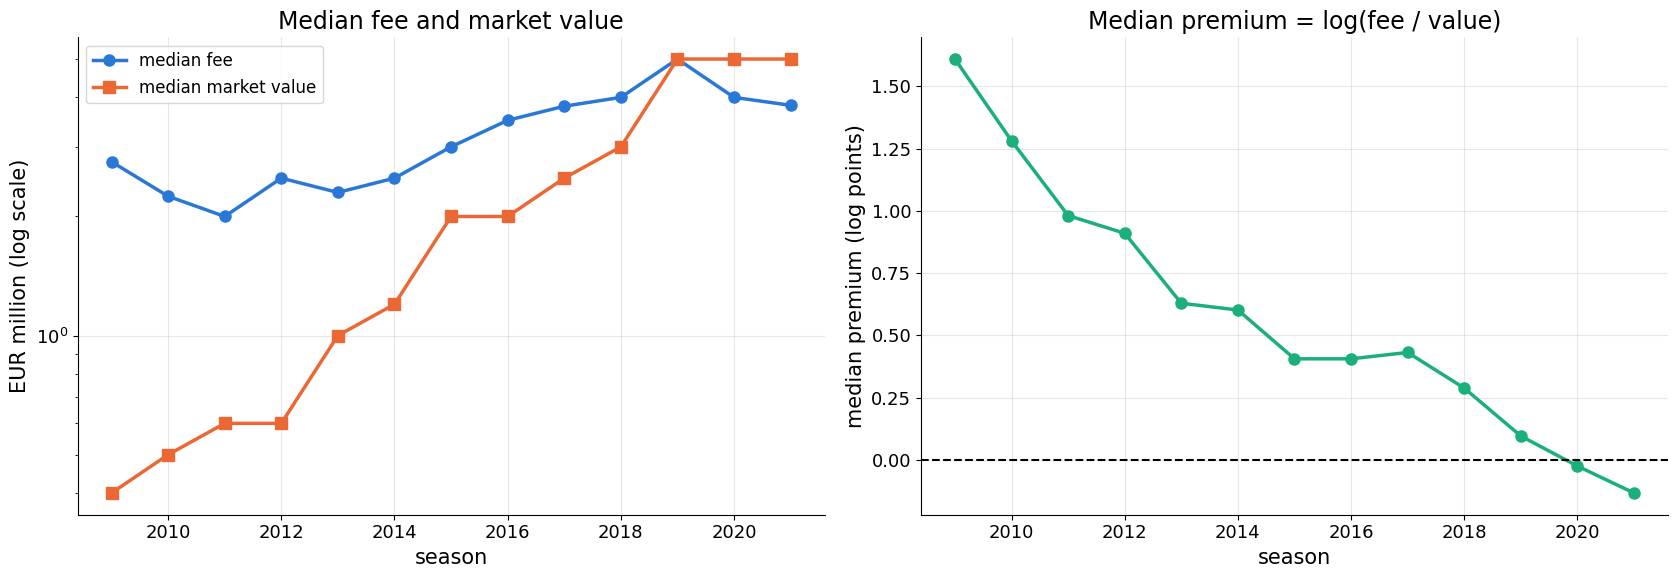

Spearman(season, premium ) = -0.290, p = 5.54e-118
Spearman(season, log_fee ) = +0.191, p = 8.49e-51
Spearman(season, log_val ) = +0.405, p = 2.19e-238


In [28]:
# Medians per season
season_tab = d.groupby("season").agg(n=("premium", "size"), median_fee=("transfer_fee_amnt", "median"),
                                     median_value=("market_val_amnt", "median"), median_premium=("premium", "median"))
print(season_tab.round(3).to_string())
save_table(season_tab, "medians_by_season.csv")

fig, ax = plt.subplots(1, 2, figsize=(17, 6))
ax[0].plot(season_tab.index, season_tab["median_fee"] / 1e6, "o-", color=COLORS[0], lw=2.5, ms=8, label="median fee")
ax[0].plot(season_tab.index, season_tab["median_value"] / 1e6, "s-", color=COLORS[1], lw=2.5, ms=8, label="median market value")
ax[0].set_yscale("log")                                   # log axis: equal steps = equal % changes
ax[0].set_xlabel("season"); ax[0].set_ylabel("EUR million (log scale)")
ax[0].set_title("Median fee and market value"); ax[0].legend()
ax[1].plot(season_tab.index, season_tab["median_premium"], "o-", color=COLORS[2], lw=2.5, ms=8)
ax[1].axhline(0, color="black", ls="--", lw=1.5)
ax[1].set_xlabel("season"); ax[1].set_ylabel("median premium (log points)")
ax[1].set_title("Median premium = log(fee / value)")
fig.tight_layout()
save_fig(fig, "fig15_trends_by_season.png")

# Spearman rank correlation with season (monotonic trend), with its significance test
for col in ["premium", "log_fee", "log_val"]:
    rho, p = stats.spearmanr(d["season"], d[col])
    print(f"Spearman(season, {col:8s}) = {rho:+.3f}, p = {p:.2e}")
rho_season, p_season = stats.spearmanr(d["season"], d["premium"])

**Where does the trend in the premium come from?** The premium is log(fee) − log(value), so it can fall either because fees fall or because market values rise faster than fees. The two Spearman correlations of `log_fee` and `log_val` with season, printed above, show which side moves more. The main model includes season dummies, so any common year-to-year shift is absorbed before leagues are compared.

subgroup      2009-2015   2016-2021
league                             
England      120% [539]   62% [592]
France        20% [326]  -16% [514]
Italy         39% [761]    4% [805]
Netherlands  -46% [183]  -58% [206]
Portugal     -19% [186]  -39% [216]
Spain         29% [314]   -6% [493]
format: % effect vs Germany [n transfers of that league in the subgroup]; * = n < 30

95% CI entirely above 0 (+), entirely below 0 (-), or containing 0 (0):
subgroup    2009-2015 2016-2021
league                         
England             +         +
France              +         -
Italy               +         0
Netherlands         -         -
Portugal            -         -
Spain               +         0


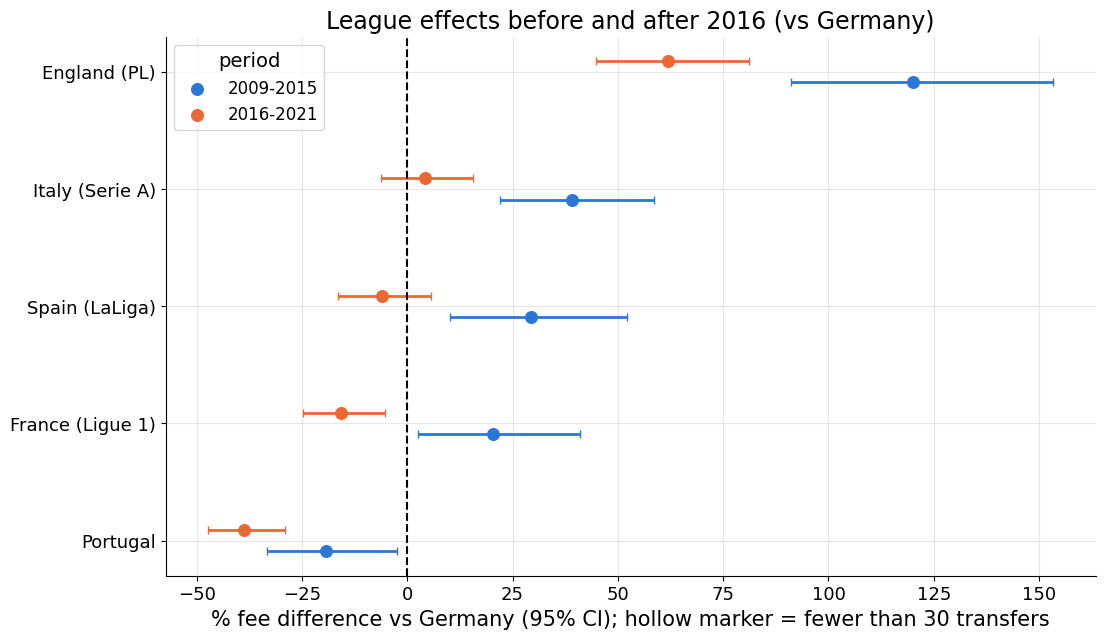

In [29]:
# Consistency over time: subgroup model separately for 2009-2015 and 2016-2021
d["period"] = np.where(d["post2016"], "2016-2021", "2009-2015")
PERIODS = ["2009-2015", "2016-2021"]
sub_period = subgroup_league_effects(d, "period", PERIODS)
show_subgroups(sub_period, PERIODS)
save_table(sub_period, "subgroup_period_league_effects.csv", index=False)
plot_subgroups(sub_period, PERIODS, "League effects before and after 2016 (vs Germany)",
               "fig16_subgroup_period.png", "period")

In [30]:
# Did the Premier League gap grow after the 2016 TV deal?
# Interaction dummy = 1 only for English buyers in 2016+; the main England dummy and the season dummies stay in.
d["eng_post2016"] = ((d["league_name"] == "England") & d["post2016"]).astype(int)
INT_FORMULA = MAIN_FORMULA + " + eng_post2016"
inter = smf.ols(INT_FORMULA, data=d).fit()
inter_hc3 = smf.ols(INT_FORMULA, data=d).fit(cov_type="HC3")
b_int = inter.params["eng_post2016"]
ci_int = inter.conf_int().loc["eng_post2016"]
b_eng_pre = inter.params["C(league_name, Treatment('Netherlands'))[T.England]"]
print(f"England vs Netherlands before 2016: b = {b_eng_pre:.3f} ({pct(b_eng_pre):+.1f}%)")
print(f"England x post2016 interaction:      b = {b_int:.3f} ({pct(b_int):+.1f}%, 95% CI {pct(ci_int[0]):+.1f}% to {pct(ci_int[1]):+.1f}%)")
print(f"   p (normal) = {inter.pvalues['eng_post2016']:.3f}   p (HC3) = {inter_hc3.pvalues['eng_post2016']:.3f}")
print(f"England vs Netherlands from 2016:   b = {b_eng_pre + b_int:.3f} ({pct(b_eng_pre + b_int):+.1f}%)")

# raw two-sample t-test: English premium before vs after 2016 (no controls)
eng = d[d["league_name"] == "England"]
t_eng = stats.ttest_ind(eng.loc[eng["post2016"], "premium"], eng.loc[~eng["post2016"], "premium"])
print(f"\nraw t-test, England premium 2016+ vs before: means {eng.loc[eng['post2016'], 'premium'].mean():.3f} vs "
      f"{eng.loc[~eng['post2016'], 'premium'].mean():.3f}, t = {t_eng.statistic:.2f}, p = {t_eng.pvalue:.3f}")

England vs Netherlands before 2016: b = 1.390 (+301.3%)
England x post2016 interaction:      b = 0.087 (+9.1%, 95% CI -4.6% to +24.8%)
   p (normal) = 0.204   p (HC3) = 0.186
England vs Netherlands from 2016:   b = 1.477 (+337.9%)

raw t-test, England premium 2016+ vs before: means 0.383 vs 1.005, t = -7.90, p = 0.000


### Takeaway

* From 2009 to 2021 the median market value rose from €0.4M to €5.0M. The median fee went from €2.75M to €3.82M (peak €5.0M in 2019). The median premium fell from **1.609 to −0.134**.
* Spearman with season: premium **−0.290** (p = 5.5 × 10⁻¹¹⁸), log fee **+0.191**, log value **+0.405**. Fees rose too, so the falling premium comes from market values rising faster than fees, not from falling fees.
* Separate models for 2009–2015 and 2016–2021 (vs Germany, holding the age band fixed):
  * **England is positive in both (+120 % and +62 %)**, and the Netherlands and Portugal are negative in both, all CIs excluding 0.
  * Italy (+39 % → +4 %) and Spain (+29 % → −6 %) are above Germany only before 2016. In 2016–2021 their CIs contain 0.
  * France switches from +20 % to −16 %, with both CIs excluding 0.
* England × post2016 interaction in the main model: **+9.1 % [−4.6, +24.8], p = 0.204 (HC3 p = 0.186).** The data give no significant evidence that the Premier League gap grew after 2016.
* The raw t-test shows English premiums falling (1.005 → 0.383, t = −7.90), but that test does not control for season.

## 8. BRANCH 4: origin of the player and the country transfer network
**Question:** do clubs pay more when they buy abroad, is this stronger in the leagues that overpay, and what does the network of countries that sell to the 7 leagues look like?

In [31]:
# Raw comparison first: two-sample t-tests on the premium
for flag in ["is_domestic", "is_foreign_player"]:
    a, b = d.loc[d[flag], "premium"], d.loc[~d[flag], "premium"]
    t = stats.ttest_ind(a, b)
    print(f"{flag:18s} True: mean {a.mean():.3f} (n={len(a)})  False: mean {b.mean():.3f} (n={len(b)})"
          f"  t = {t.statistic:.2f}, p = {t.pvalue:.2e}")

# Controlled effect from the main model
dom = main_coefs.set_index("term").loc["is_domestic=True"]
print(f"\nmain model: domestic purchase {dom['pct']:+.1f}% (95% CI {dom['pct_lo']:+.1f}% to {dom['pct_hi']:+.1f}%), "
      f"p = {dom['p']:.2e}, HC3 p = {dom['p_HC3']:.2e}")
print(f"equivalently, buying abroad costs {pct(-dom['b']):+.1f}% more than a comparable domestic purchase")

is_domestic        True: mean 0.368 (n=2771)  False: mean 0.373 (n=3292)  t = -0.14, p = 8.86e-01
is_foreign_player  True: mean 0.421 (n=4232)  False: mean 0.256 (n=1831)  t = 4.25, p = 2.13e-05

main model: domestic purchase -18.7% (95% CI -22.9% to -14.3%), p = 2.81e-14, HC3 p = 2.09e-14
equivalently, buying abroad costs +23.0% more than a comparable domestic purchase


In [32]:
# Same effect inside each buying league: one model per league
LEAGUE_ONLY = ("log_fee ~ log_val + C(pos_group, Treatment('ATT')) + C(age_band, Treatment('<=21'))"
               " + C(season) + is_domestic")
rows = []
for l in LEAGUES:
    sub = d[d["league_name"] == l]
    m = smf.ols(LEAGUE_ONLY, data=sub).fit()
    m_r = smf.ols(LEAGUE_ONLY, data=sub).fit(cov_type="HC3")
    b, (lo, hi) = m.params["is_domestic[T.True]"], m.conf_int().loc["is_domestic[T.True]"]
    rows.append({"league": l, "n": len(sub), "share_domestic": sub["is_domestic"].mean(),
                 "domestic_pct": pct(b), "pct_lo": pct(lo), "pct_hi": pct(hi),
                 "abroad_premium_pct": pct(-b), "p": m.pvalues["is_domestic[T.True]"],
                 "p_HC3": m_r.pvalues["is_domestic[T.True]"]})
dom_by_league = pd.DataFrame(rows).set_index("league").loc[list(lg["league"][::-1]) + [LEAGUE_REF]]   # biggest overpayer first
print(fmt_p(dom_by_league.round(3)).to_string())
save_table(dom_by_league, "domestic_effect_by_league.csv")

                n  share_domestic  domestic_pct  pct_lo  pct_hi  abroad_premium_pct        p    p_HC3
league                                                                                               
England      1131           0.401       -16.871 -25.758  -6.920              20.295  1.0e-03  2.0e-03
Italy        1566           0.549         2.083  -8.407  13.774              -2.040  7.1e-01  7.0e-01
Spain         807           0.421       -36.416 -45.403 -25.949              57.272  0.0e+00  0.0e+00
Germany       928           0.442       -23.514 -32.709 -13.063              30.743  0.0e+00  0.0e+00
France        840           0.471       -21.566 -31.536 -10.143              27.495  0.0e+00  1.0e-03
Portugal      402           0.318       -46.259 -58.135 -31.015              86.078  0.0e+00  0.0e+00
Netherlands   389           0.476       -26.759 -42.201  -7.190              36.535  1.0e-02  1.1e-02


In [33]:
# Directed weighted graph: node = country, edge = seller country -> buyer country
# weights: number of transfers ("count") and total fee in EUR ("fee")
edges = (d.groupby(["counter_team_country", "team_country"])
           .agg(count=("transfer_fee_amnt", "size"), fee=("transfer_fee_amnt", "sum")).reset_index())
G = nx.DiGraph()
for _, e in edges.iterrows():
    G.add_edge(e["counter_team_country"], e["team_country"], count=int(e["count"]), fee=float(e["fee"]))
BUYERS = sorted(d["team_country"].unique())
print(f"nodes (countries): {G.number_of_nodes()} | edges (seller -> buyer pairs): {G.number_of_edges()}")
print(f"self-loops (domestic transfers): {nx.number_of_selfloops(G)}")

# Domestic share = self-loop transfers / all transfers bought by that country
dom_share = pd.DataFrame({
    "bought_total": [G.in_degree(c, weight="count") for c in BUYERS],
    "bought_domestic": [G[c][c]["count"] if G.has_edge(c, c) else 0 for c in BUYERS]}, index=BUYERS)
dom_share["domestic_share"] = dom_share["bought_domestic"] / dom_share["bought_total"]
print(dom_share.sort_values("domestic_share", ascending=False).round(3).to_string())
save_table(dom_share, "network_domestic_share.csv")

# Remove self-loops: from here on the network describes cross-border transfers only
G.remove_edges_from(list(nx.selfloop_edges(G)))
print(f"\nafter removing self-loops: {G.number_of_edges()} edges, "
      f"{sum(nx.get_edge_attributes(G, 'count').values()):,} cross-border transfers")

nodes (countries): 80 | edges (seller -> buyer pairs): 331
self-loops (domestic transfers): 7
             bought_total  bought_domestic  domestic_share
Italy                1566              859           0.549
Netherlands           389              185           0.476
France                840              396           0.471
Germany               928              410           0.442
Spain                 807              340           0.421
England              1131              453           0.401
Portugal              402              128           0.318

after removing self-loops: 324 edges, 3,292 cross-border transfers


In [34]:
# Node table: degree (number of partner countries) and strength (sum of edge weights)
nodes = pd.DataFrame({
    "in_degree": dict(G.in_degree()), "out_degree": dict(G.out_degree()),
    "in_strength_n": dict(G.in_degree(weight="count")), "out_strength_n": dict(G.out_degree(weight="count")),
    "fees_in_EURm": {k: v / 1e6 for k, v in G.in_degree(weight="fee")},     # fees paid when buying
    "fees_out_EURm": {k: v / 1e6 for k, v in G.out_degree(weight="fee")},   # fees received when selling
})
nodes["net_balance_EURm"] = nodes["fees_in_EURm"] - nodes["fees_out_EURm"]   # > 0: net spender on cross-border deals
nodes["total_strength_n"] = nodes["in_strength_n"] + nodes["out_strength_n"]
nodes = nodes.sort_values("total_strength_n", ascending=False)
print(nodes.head(15).round(1).to_string())
save_table(nodes, "network_nodes.csv")

             in_degree  out_degree  in_strength_n  out_strength_n  fees_in_EURm  fees_out_EURm  net_balance_EURm  total_strength_n
England             47           6            678             262        9459.3         2678.4            6780.9               940
Italy               55           6            707             210        4269.9         2884.7            1385.2               917
Spain               37           6            467             279        4975.0         3983.4             991.6               746
France              54           6            444             298        3245.2         3409.7            -164.4               742
Germany             48           6            518             188        3169.8         2481.2             688.6               706
Portugal            45           6            274             182        1096.7         2164.5           -1067.8               456
Netherlands         38           6            204             171         514.9    

In [35]:
# Dyad census and reciprocity among the 7 buying countries only
# (the other countries never appear as buyers, so their dyads could never be mutual)
H = G.subgraph(BUYERS)
mutual = asym = null = 0
for i, u in enumerate(BUYERS):
    for v in BUYERS[i + 1:]:
        links = H.has_edge(u, v) + H.has_edge(v, u)
        mutual += links == 2; asym += links == 1; null += links == 0
print(f"dyad census among the 7 buyers: mutual = {mutual}, asymmetric = {asym}, null = {null} (of 21 pairs)")
print(f"reciprocity (share of directed edges that are reciprocated): {nx.reciprocity(H):.3f}")
flows = nx.to_pandas_adjacency(H, weight="count", nodelist=BUYERS).astype(int)
print("\ntransfers between the 7 (row = seller, column = buyer):")
print(flows.to_string())
save_table(flows, "network_flows_7_buyers.csv")

dyad census among the 7 buyers: mutual = 21, asymmetric = 0, null = 0 (of 21 pairs)
reciprocity (share of directed edges that are reciprocated): 1.000

transfers between the 7 (row = seller, column = buyer):
             England  France  Germany  Italy  Netherlands  Portugal  Spain
England            0      51       50     65           15        13     68
France           112       0       55     50           10        13     58
Germany           63      25        0     32           27         8     33
Italy             61      44       33      0            4        15     53
Netherlands       53      21       39     37            0         6     15
Portugal          41      42       12     27            2         0     58
Spain            101      39       36     72            4        27      0


In [36]:
# Betweenness centrality: how often a country lies on shortest paths.
# Strong links should be "short", so distance = 1 / number of transfers.
for u, v, e in G.edges(data=True):
    e["dist"] = 1 / e["count"]
btw = pd.Series(nx.betweenness_centrality(G, weight="dist", normalized=True)).sort_values(ascending=False)

# Undirected weighted version (add both directions) for eigenvector centrality and communities
U = nx.Graph()
for u, v, e in G.edges(data=True):
    w = U[u][v]["count"] if U.has_edge(u, v) else 0
    U.add_edge(u, v, count=w + e["count"])
# eigenvector centrality: a country is central if it trades a lot with other central countries
eig = pd.Series(nx.eigenvector_centrality(U, weight="count", max_iter=1000)).sort_values(ascending=False)

central = pd.DataFrame({"betweenness_country": btw.head(10).index, "betweenness": btw.head(10).values,
                        "eigenvector_country": eig.head(10).index, "eigenvector": eig.head(10).values})
print(central.round(4).to_string(index=False))
save_table(pd.DataFrame({"betweenness": btw, "eigenvector": eig}), "network_centrality.csv")

betweenness_country  betweenness eigenvector_country  eigenvector
              Italy       0.0235             England       0.4889
            Germany       0.0180               Spain       0.4261
              Spain       0.0153              France       0.4027
             France       0.0129               Italy       0.4008
            England       0.0118             Germany       0.3245
           Portugal       0.0071            Portugal       0.2314
        Netherlands       0.0036         Netherlands       0.1852
            Algeria       0.0000              Brazil       0.1397
    North Macedonia       0.0000             Belgium       0.1007
             Poland       0.0000           Argentina       0.0888


In [37]:
# Fast-greedy community detection: merge groups step by step while modularity increases
comms = nx.community.greedy_modularity_communities(U, weight="count")
Q = nx.community.modularity(U, comms, weight="count")
print(f"number of communities: {len(comms)} | modularity Q = {Q:.3f}")
comm_rows = []
for i, c in enumerate(comms):
    members = sorted(c, key=lambda x: -nodes.loc[x, "total_strength_n"])
    comm_rows.append({"community": i + 1, "size": len(c), "members": ", ".join(members)})
    print(f"\ncommunity {i + 1} ({len(c)} countries): {', '.join(members)}")
save_table(pd.DataFrame(comm_rows), "network_communities.csv", index=False)

# Degree assortativity: do well-connected countries link to other well-connected countries?
assort_dir = nx.degree_assortativity_coefficient(G)       # directed: out-degree of seller vs in-degree of buyer
assort_und = nx.degree_assortativity_coefficient(U)       # undirected version
print(f"\ndegree assortativity: directed = {assort_dir:.3f}, undirected = {assort_und:.3f}")

number of communities: 2 | modularity Q = 0.079

community 1 (51 countries): England, Italy, Spain, France, Portugal, Brazil, Belgium, Argentina, Croatia, Serbia, Turkey, Uruguay, Russia, Mexico, Colombia, Scotland, Chile, Romania, United States, Slovenia, Slovakia, Tunisia, Hungary, Cyprus, Egypt, Morocco, Peru, Paraguay, Ireland, Algeria, Qatar, Lithuania, Saudi Arabia, Mali, DR Congo, United Arab Emirates, Mozambique, Ghana, Costa Rica, Congo, Gabon, Latvia, Northern Ireland, Uzbekistan, Moldova, Azerbaijan, Panama, Cote d'Ivoire, Montenegro, Angola, Kazakhstan

community 2 (29 countries): Germany, Netherlands, Switzerland, Denmark, Austria, Greece, Sweden, Poland, Norway, Czech Republic, Ukraine, Japan, Bulgaria, Venezuela, Israel, Ecuador, South Africa, China, Australia, Finland, Korea, South, North Macedonia, Belarus, Georgia, Nigeria, Iran, Senegal, Bosnia-Herzegovina, Kosovo

degree assortativity: directed = -0.138, undirected = -0.842


In [38]:
# Chi-square test of independence: does the seller country depend on the buyer country?
# All transfers (domestic included). Expected count E_ij = row_i * col_j / N must be >= 5,
# so a seller needs at least 5 * N / (smallest buyer total) transfers; smaller sellers go into "Other".
N = len(d)
min_col = d["team_country"].value_counts().min()
min_row = int(np.ceil(5 * N / min_col))
seller_tot = d["counter_team_country"].value_counts()
small = seller_tot[seller_tot < min_row].index
seller = d["counter_team_country"].where(~d["counter_team_country"].isin(small), "Other")
obs = pd.crosstab(seller, d["team_country"])
chi2, p_chi, dof, expected = stats.chi2_contingency(obs)
print(f"sellers need >= {min_row} transfers; {len(small)} of {len(seller_tot)} seller countries grouped into 'Other'")
print(f"table size: {obs.shape[0]} sellers x {obs.shape[1]} buyers | smallest expected count = {expected.min():.1f}")
print(f"chi-square = {chi2:.1f}, df = {dof}, p = {p_chi:.2e}")
print("\nobserved table:")
print(obs.to_string())
save_table(obs, "chi2_seller_buyer_observed.csv")

sellers need >= 78 transfers; 68 of 80 seller countries grouped into 'Other'
table size: 13 sellers x 7 buyers | smallest expected count = 5.1
chi-square = 8397.5, df = 72, p = 0.00e+00

observed table:
team_country          England  France  Germany  Italy  Netherlands  Portugal  Spain
counter_team_country                                                               
Argentina                   8      10        8     40            5        26     33
Belgium                    30      33       17     28           10         8     13
Brazil                     18      28       20     57            2        66     23
Denmark                    12       8       16     15           18         2      8
England                   453      51       50     65           15        13     68
France                    112     396       55     50           10        13     58
Germany                    63      25      410     32           27         8     33
Italy                      61      44    

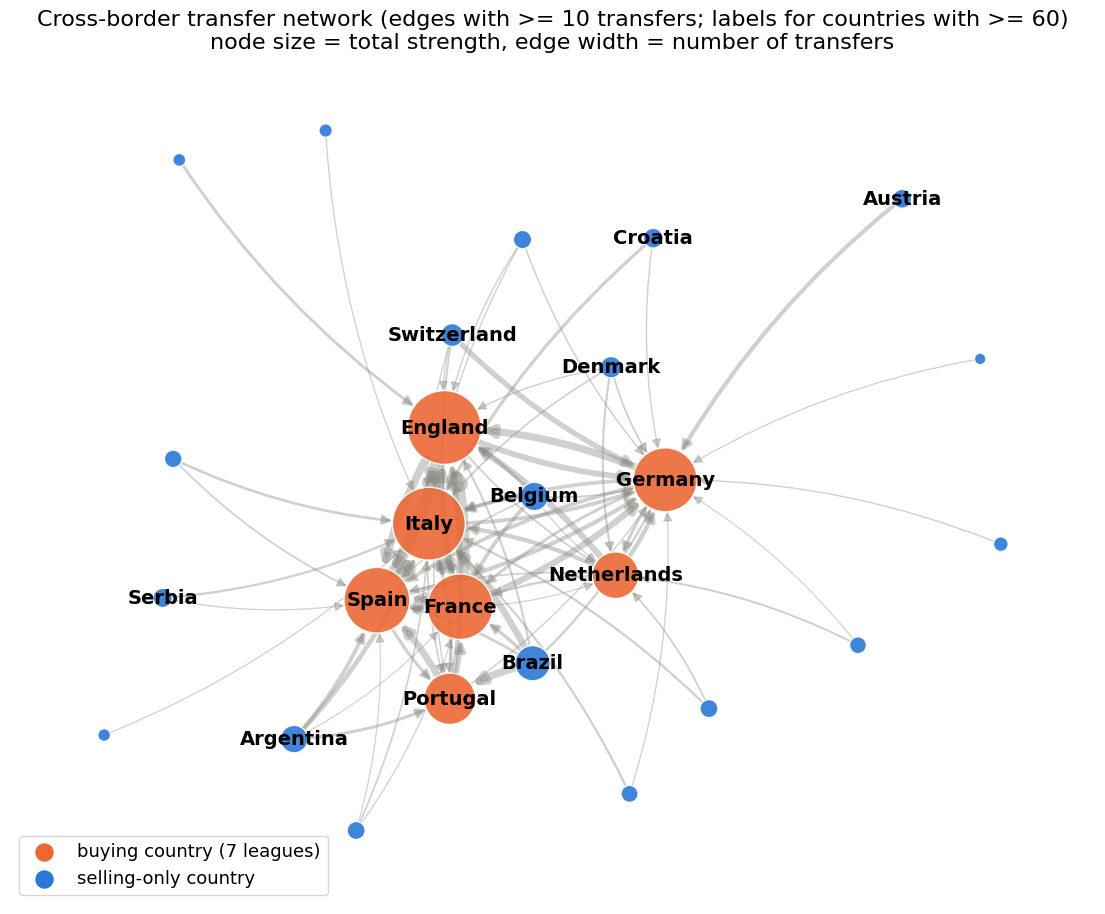

shown: 26 countries, 85 edges


In [39]:
# Network figure: Fruchterman-Reingold layout (force-directed), fixed seed for reproducibility
EDGE_MIN, LABEL_MIN = 10, 60          # show edges with >= 10 transfers; label countries with >= 60 transfers in+out
P = nx.DiGraph([(u, v, e) for u, v, e in G.edges(data=True) if e["count"] >= EDGE_MIN])
pos = nx.spring_layout(P.to_undirected(), weight=None, seed=SEED, k=1.2, iterations=200)   # spring_layout = Fruchterman-Reingold
size = [nodes.loc[n, "total_strength_n"] * 3 for n in P.nodes()]
width = [e["count"] / 12 for _, _, e in P.edges(data=True)]
node_col = [COLORS[1] if n in BUYERS else COLORS[0] for n in P.nodes()]

fig, ax = plt.subplots(figsize=(14, 11))
nx.draw_networkx_edges(P, pos, ax=ax, width=width, alpha=0.4, edge_color=GREY, arrows=True,
                       arrowsize=14, connectionstyle="arc3,rad=0.1", node_size=size)
nx.draw_networkx_nodes(P, pos, ax=ax, node_size=size, node_color=node_col, alpha=0.9, edgecolors="white")
labels = {n: n for n in P.nodes() if nodes.loc[n, "total_strength_n"] >= LABEL_MIN}
nx.draw_networkx_labels(P, pos, labels=labels, ax=ax, font_size=14, font_weight="bold")
ax.scatter([], [], color=COLORS[1], s=150, label="buying country (7 leagues)")
ax.scatter([], [], color=COLORS[0], s=150, label="selling-only country")
ax.legend(loc="lower left", fontsize=13)
ax.set_title(f"Cross-border transfer network (edges with >= {EDGE_MIN} transfers; labels for countries with >= {LABEL_MIN})\n"
             "node size = total strength, edge width = number of transfers", fontsize=16)
ax.axis("off")
save_fig(fig, "fig17_transfer_network.png")
print(f"shown: {P.number_of_nodes()} countries, {P.number_of_edges()} edges")

**Limitation.** The dataset only contains purchases made by clubs in the 7 leagues. Sales to clubs elsewhere (e.g. a Brazilian club buying from Portugal) are missing, so countries outside the 7 can only appear as sellers. In-strength, reciprocity and centrality must be read as "within the market of the 7 buying leagues", not the global transfer market.

### Takeaway

* **Raw:** domestic and cross-border deals have the same mean premium (0.368 vs 0.373, t-test p = 0.886). Foreign-nationality players have a higher mean premium than nationals (0.421 vs 0.256, p = 2.1 × 10⁻⁵).
* **Controlled (main model):** a domestic purchase costs **−18.7 % [−22.9, −14.3]**, which means buying abroad costs **+23.0 %** more.
* **By league, buying abroad costs more** in England (+20 %), the Netherlands (+37 %), France (+27 %), Germany (+31 %), Spain (+57 %) and Portugal (+86 %), all p ≤ 0.011. In **Italy there is no such effect (−2 %, p = 0.71)**. The two leagues that pay most do not have the largest abroad premiums.
* **Network:** 80 countries and 331 seller→buyer edges, including 7 self-loops. The domestic share ranges from **54.9 % (Italy)** to **31.8 % (Portugal)**. After removing self-loops there are 324 edges and 3,292 cross-border transfers.
* **Net fee balance** on cross-border deals: England **+€6,781M** (largest net spender), Italy +€1,385M, Spain +€992M, Germany +€689M; France −€164M, the Netherlands −€976M, Portugal −€1,068M. Brazil is the largest selling-only country (214 transfers, €1,445M).
* Among the 7 buyers, all **21 dyads are mutual** (reciprocity 1.000).
* Betweenness is non-zero only for the 7 buyers (Italy highest, 0.0235). Eigenvector centrality is highest for England (0.489), then Spain, France and Italy. Brazil (0.140) is the top non-buyer.
* Fast greedy finds **2 communities with modularity Q = 0.079**: {England, Italy, Spain, France, Portugal, Brazil, Belgium, Argentina, …} and {Germany, Netherlands, Switzerland, Denmark, Austria, …}.
* Degree assortativity is −0.138 (directed) and −0.842 (undirected).
* **Chi-square:** 68 of 80 sellers are grouped into "Other" (a seller needs ≥ 78 transfers). The table is 13 × 7 with smallest expected count 5.1. **χ² = 8,397.5, df = 72, p ≈ 0**, so the seller country is not independent of the buyer country.

## 9. Robustness
**Question:** do the league effects depend on how we removed outliers or on extreme deal sizes, and could selective fee disclosure bias the results?

main: n = 6,063 | (a) |premium| <= ln(20) = 3.00: n = 5,797 | (b) EUR 1-20M: n = 3,406


subgroup  (a) |premium| <= ln 20  (b) value EUR 1-20M  main (z-rule)
league                                                              
England                    263.8                273.9          320.0
Italy                      139.0                139.0          162.8
Spain                      109.2                101.0          134.3
Germany                    104.3                101.1          121.6
France                      99.6                 85.4          117.3
Portugal                    38.9                 35.6           43.7

lower end of the 95% CI (% vs Netherlands):
subgroup  (a) |premium| <= ln 20  (b) value EUR 1-20M  main (z-rule)
league                                                              
England                    223.9                216.5          271.7
Italy                      114.1                102.8          134.0
Spain                       85.3                 69.0          106.2
Germany                     81.7                 69.7     

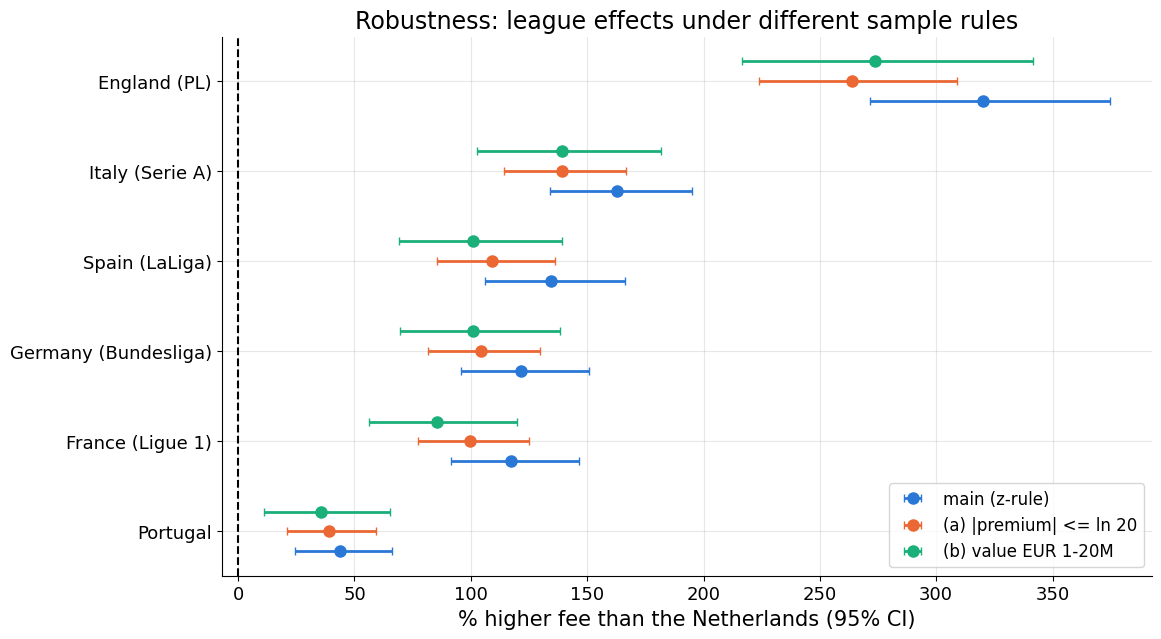

In [40]:
# (a) stricter trimming: keep |premium| <= ln(20), i.e. fee between 1/20 and 20 times the value (instead of the z-rule)
strict = make_features(d_pre[d_pre["premium"].abs() <= np.log(20)], mean_age=MEAN_AGE)
# (b) only market values between EUR 1M and 20M (z-rule sample)
band = d[d["market_val_amnt"].between(1e6, 20e6)]
print(f"main: n = {len(d):,} | (a) |premium| <= ln(20) = {np.log(20):.2f}: n = {len(strict):,} | (b) EUR 1-20M: n = {len(band):,}")

rob = []
for name, data in [("main (z-rule)", d), ("(a) |premium| <= ln 20", strict), ("(b) value EUR 1-20M", band)]:
    m = smf.ols(MAIN_FORMULA, data=data).fit()
    eff = league_effects(m, LEAGUE_REF)
    eff["subgroup"], eff["n_subgroup"], eff["elasticity"] = name, int(m.nobs), m.params["log_val"]
    eff["n_league"] = eff["league"].map(data["league_name"].value_counts())
    eff["flag_n_lt_30"] = eff["n_league"] < 30
    rob.append(eff)
rob = pd.concat(rob, ignore_index=True)
print(rob.pivot(index="league", columns="subgroup", values="pct").loc[lg["league"][::-1]].round(1).to_string())
print("\nlower end of the 95% CI (% vs Netherlands):")
print(rob.pivot(index="league", columns="subgroup", values="pct_lo").loc[lg["league"][::-1]].round(1).to_string())
print("\nelasticity:", rob.groupby("subgroup")["elasticity"].first().round(3).to_dict())
save_table(rob, "robustness_league_effects.csv", index=False)

# grouped plot (reference = Netherlands here, like the main model)
ROB_ORDER = ["main (z-rule)", "(a) |premium| <= ln 20", "(b) value EUR 1-20M"]
leagues_nl = list(lg["league"])
fig, ax = plt.subplots(figsize=(12, 7))
for i, g in enumerate(ROB_ORDER):
    t = rob[rob["subgroup"] == g].set_index("league").reindex(leagues_nl)
    y = np.arange(len(leagues_nl)) + (i - 1) * 0.22
    ax.errorbar(t["pct"], y, xerr=[t["pct"] - t["pct_lo"], t["pct_hi"] - t["pct"]], fmt="o", color=COLORS[i],
                ms=8, capsize=3, lw=2, label=g)
ax.axvline(0, color="black", ls="--", lw=1.5)
ax.set_yticks(range(len(leagues_nl))); ax.set_yticklabels([LEAGUE_LABEL[l] for l in leagues_nl])
ax.set_xlabel("% higher fee than the Netherlands (95% CI)")
ax.set_title("Robustness: league effects under different sample rules")
ax.legend(loc="lower right")
save_fig(fig, "fig18_robustness.png")

In [41]:
# Disclosure bias: which permanent incoming transfers end up in the sample?
# pool = permanent incoming transfers BEFORE requiring a fee (section 1)
pool = pool.copy()
pool["league_name"] = pool["league"].map(LEAGUE_NAME)
pool["fee_disclosed"] = pool["transfer_fee_amnt"].notna()            # a number is published (0 = free transfer)
pool["paid_fee"] = pool["transfer_fee_amnt"] > 0
pool["in_sample"] = pool.index.isin(d.index)                        # survived every cleaning step
disc = pool.groupby("league_name").agg(n_permanent=("in_sample", "size"),
                                       pct_fee_disclosed=("fee_disclosed", "mean"),
                                       pct_paid_fee=("paid_fee", "mean"),
                                       pct_in_sample=("in_sample", "mean"))
disc[["pct_fee_disclosed", "pct_paid_fee", "pct_in_sample"]] *= 100
disc = disc.sort_values("pct_in_sample", ascending=False)
print(disc.round(1).to_string())
save_table(disc, "disclosure_by_league.csv")

# chi-square: is ending up in the sample independent of the buying league?
ct_ins = pd.crosstab(pool["league_name"], pool["in_sample"])
chi2_d, p_d, dof_d, exp_d = stats.chi2_contingency(ct_ins)
print(f"\nchi-square league x in_sample: chi2 = {chi2_d:.1f}, df = {dof_d}, p = {p_d:.2e}, min expected = {exp_d.min():.0f}")

# are the dropped deals cheaper or more expensive players than the kept ones? (only rows with a market value)
mv = pool[pool["market_val_amnt"] > 0]
kept_drop = mv.groupby(["league_name", "in_sample"])["market_val_amnt"].median().unstack() / 1e6
kept_drop.columns = ["median_value_dropped_EURm", "median_value_kept_EURm"]
kept_drop["n_dropped_with_value"] = mv[~mv["in_sample"]].groupby("league_name").size()
print("\n", kept_drop.round(2).to_string())
save_table(kept_drop, "kept_vs_dropped_value.csv")

             n_permanent  pct_fee_disclosed  pct_paid_fee  pct_in_sample
league_name                                                             
England             2308               75.8          59.7           49.0
Italy               3502               73.7          54.4           44.7
Germany             2225               70.7          49.6           41.7
Spain               2145               75.0          43.8           37.6
France              2456               63.7          40.6           34.2
Netherlands         2383               57.7          18.6           16.3
Portugal            2964               55.5          15.2           13.6

chi-square league x in_sample: chi2 = 1370.7, df = 6, p = 5.27e-293, min expected = 723

              median_value_dropped_EURm  median_value_kept_EURm  n_dropped_with_value
league_name                                                                         
England                           1.00                    3.50                   5

**Direction of the possible bias.** The share of permanent incoming transfers that reach the sample ranges from **49.0 % (England)** to **16.3 % (Netherlands)** and **13.6 % (Portugal)**. This is not independent of the league (χ² = 1,370.7, df = 6, p ≈ 10⁻²⁹³). In every league the dropped deals involve cheaper players than the kept ones (e.g. England €1.0M vs €3.5M, Portugal €0.32M vs €1.35M). So the sample over-represents expensive players, and it does so most for the Netherlands and Portugal. One possible direction follows if undisclosed fees tend to be small (clubs disclose big fees more readily): the sample then overstates typical fees most in the low-disclosure leagues (Netherlands, Portugal), so their premiums are biased upward and the true gap to England would be larger, not smaller. If instead undisclosed fees were large, the bias would go the other way. The data cannot tell which is true.

### Takeaway

* **(a) |premium| ≤ ln 20** (n = 5,797) and **(b) market value €1–20M** (n = 3,406) both give smaller league effects than the main model, and the order of the leagues is unchanged.
* England vs the Netherlands: **+320 % main, +264 % (a), +274 % (b)**. Italy is second in all three (+163 / +139 / +139 %). Portugal is lowest in all three (+44 / +39 / +36 %). Every league's 95 % CI lower bound stays above 0 in all three samples (smallest: Portugal in (b), +11 %).
* The elasticity is 0.523 (main), 0.590 (a) and 0.563 (b).
* Disclosure: the share of permanent buys with a paid fee is 59.7 % for England and 15.2 % for Portugal. The share ending in the sample is 49.0 % vs 13.6 %. League and inclusion are dependent (χ² = 1,370.7, p ≈ 10⁻²⁹³), and dropped deals have lower median market values in every league.

## 10. Summary for slides
**Question:** what are the key numbers to put on the slides?

In [42]:
# Subgroup consistency: for each league, is its effect vs Germany on the same side as in the pooled model
# in every subgroup (age, position, value tier, period)? Cells with n < 30 are excluded.
main_de = smf.ols(MAIN_FORMULA.replace("Treatment('Netherlands')", "Treatment('Germany')"), data=d).fit()
pooled_de = league_effects(main_de, "Germany").set_index("league")["pct"]
all_sub = pd.concat([sub_age.assign(split="age"), sub_pos.assign(split="position"),
                     sub_tier.assign(split="value tier"), sub_period.assign(split="period")])
valid = all_sub[~all_sub["flag_n_lt_30"]].copy()
valid["same_sign"] = np.sign(valid["pct"]) == valid["league"].map(np.sign(pooled_de))
valid["same_sign_signif"] = valid["same_sign"] & ((valid["pct_lo"] > 0) | (valid["pct_hi"] < 0))
consist = valid.groupby("league").agg(subgroups=("same_sign", "size"), same_sign=("same_sign", "sum"),
                                      same_sign_and_CI_excludes_0=("same_sign_signif", "sum"))
consist["pooled_pct_vs_Germany"] = pooled_de
consist["holds_everywhere"] = np.where(consist["same_sign"] == consist["subgroups"], "yes", "no")
consist = consist.sort_values("pooled_pct_vs_Germany", ascending=False)
print(consist.round(1).to_string())
save_table(consist, "subgroup_consistency.csv")

# is England the top league in every subgroup?
top = all_sub[all_sub.groupby(["split", "subgroup"])["pct"].transform("max") == all_sub["pct"]]
eng_top = (top["league"] == "England").sum()
n_sub = all_sub.groupby(["split", "subgroup"]).ngroups
print(f"\nEngland has the largest effect in {eng_top} of {n_sub} subgroups (incl. flagged cells)")

             subgroups  same_sign  same_sign_and_CI_excludes_0  pooled_pct_vs_Germany holds_everywhere
league                                                                                                
England             13         13                           13                   89.5              yes
Italy               13         12                            7                   18.6               no
Spain               13          9                            3                    5.7               no
France              13          7                            1                   -2.0               no
Portugal            12         12                           11                  -35.1              yes
Netherlands         12         12                           12                  -54.9              yes

England has the largest effect in 13 of 13 subgroups (incl. flagged cells)


In [43]:
# Key numbers in one dictionary, saved as tables/key_results.csv
def fmt_ci(v, lo, hi):
    return f"{v:+.1f}% [{lo:+.1f}, {hi:+.1f}]"

key = {
    "sample_size": len(d),
    "outliers_dropped_z_gt_3": len(outliers),
    "anova_league_F": round(anova_league.statistic, 2),
    "anova_league_p": f"{anova_league.pvalue:.2e}",
    "tukey_league_significant_pairs": f"{tk_league['reject'].sum()} of {len(tk_league)}",
    "main_model_R2": round(main.rsquared, 3),
}
for _, r in lg.sort_values("pct", ascending=False).iterrows():
    key[f"league_pct_vs_NL_{r['league']}"] = fmt_ci(r["pct"], r["pct_lo"], r["pct_hi"])
for _, r in std_player.iterrows():
    key[f"std_player_ratio_{r['league']}"] = f"{r['ratio']:.2f} [{r['ratio_lo']:.2f}, {r['ratio_hi']:.2f}]"
key["elasticity_log_val"] = round(b_val, 3)
for _, r in main_coefs[main_coefs["term"].str.match("age_band=|pos_group=")].iterrows():
    key[f"main_{r['term']}"] = fmt_ci(r["pct"], r["pct_lo"], r["pct_hi"])
key["peak_age"] = round(peak_age, 1)
key["delta_R2_position"] = round(dR2_pos, 4)
key["delta_R2_age_given_position"] = round(dR2_age, 4)
key["anova_age_F_p"] = f"F={anova_age.statistic:.2f}, p={anova_age.pvalue:.2e}"
key["anova_position_F_p"] = f"F={anova_pos.statistic:.2f}, p={anova_pos.pvalue:.2e}"
key["anova_value_tier_F_p"] = f"F={anova_tier.statistic:.2f}, p={anova_tier.pvalue:.2e}"
for l, r in consist.iterrows():
    key[f"subgroup_consistency_{l}"] = f"{r['holds_everywhere']} ({int(r['same_sign'])}/{int(r['subgroups'])} same sign vs Germany)"
key["england_top_in_subgroups"] = f"{eng_top} of {n_sub}"
key["spearman_season_premium"] = f"rho={rho_season:.3f}, p={p_season:.2e}"
key["england_x_post2016"] = f"{fmt_ci(pct(b_int), pct(ci_int[0]), pct(ci_int[1]))}, p={inter.pvalues['eng_post2016']:.3f}, HC3 p={inter_hc3.pvalues['eng_post2016']:.3f}"
key["is_domestic_pct"] = fmt_ci(dom["pct"], dom["pct_lo"], dom["pct_hi"])
key["network_modularity"] = round(Q, 3)
key["network_communities"] = len(comms)
key["reciprocity_7_buyers"] = round(nx.reciprocity(H), 3)
key["degree_assortativity_directed"] = round(assort_dir, 3)
key["chi2_seller_x_buyer"] = f"chi2={chi2:.1f}, df={dof}, p={p_chi:.2e}, {len(small)} sellers grouped"
key["chi2_league_x_in_sample"] = f"chi2={chi2_d:.1f}, df={dof_d}, p={p_d:.2e}"
for _, r in rob[rob["subgroup"] != "main (z-rule)"].iterrows():
    key[f"robust_{r['subgroup'][:3]}_{r['league']}"] = f"{r['pct']:+.1f}%"

key_df = pd.DataFrame(list(key.items()), columns=["key", "value"])
save_table(key_df, "key_results.csv", index=False)
for k, v in key.items():
    print(f"{k:42s} {v}")

print("\nexported files:")
for folder in [FIG_DIR, TAB_DIR]:
    for f in sorted(os.listdir(folder)):
        print(f"  {folder}/{f}")

sample_size                                6063
outliers_dropped_z_gt_3                    34
anova_league_F                             40.24
anova_league_p                             2.67e-48
tukey_league_significant_pairs             15 of 21
main_model_R2                              0.475
league_pct_vs_NL_England                   +320.0% [+271.7, +374.5]
league_pct_vs_NL_Italy                     +162.8% [+134.0, +195.0]
league_pct_vs_NL_Spain                     +134.3% [+106.2, +166.3]
league_pct_vs_NL_Germany                   +121.6% [+95.9, +150.8]
league_pct_vs_NL_France                    +117.3% [+91.7, +146.3]
league_pct_vs_NL_Portugal                  +43.7% [+24.3, +66.2]
std_player_ratio_England                   2.44 [2.13, 2.79]
std_player_ratio_Italy                     1.52 [1.34, 1.73]
std_player_ratio_Spain                     1.36 [1.18, 1.56]
std_player_ratio_Germany                   1.29 [1.12, 1.47]
std_player_ratio_France                    1.26 [1.10, 1.

### Takeaway

* **Main answer.** For a comparable player, England pays the most: **+320 % vs the Netherlands, +90 % vs Germany**. It does so in **all 13 subgroups** (3 age groups, 4 positions, 4 value quartiles, 2 periods), with the CI above 0 every time. It is also the only league with a standard-player ratio far above 1 (**2.44**).
* The Netherlands and Portugal pay less than Germany in every subgroup with n ≥ 30 (12 of 12). Their standard-player ratios are below 1 (0.58 and 0.83).
* Italy is above Germany in 12 of 13 subgroups, but its CI excludes 0 in only 7. Spain is above Germany in only 9 of 13, and its CI excludes 0 in only 3 (≤21, Q1, 2009–2015). France has the same sign as the pooled model in only 7 of 13 subgroups.
* The position, value-quartile and period models hold the age band fixed (`age_band3`, 3 bands); the age-group models cannot, since age is constant inside them. England has the largest effect in **13 of 13** subgroups.
* By the definition used here, **England overpays systematically**. Italy overpays in the pooled model but not consistently across subgroups. Spain's small pooled lead over Germany (+5.7 %) comes mainly from young, cheap and pre-2016 deals. The Netherlands and Portugal systematically pay less.
* The full list of numbers is printed above and saved in `tables/key_results.csv`.

## 11. Slide-ready figures
**Question:** can the key figures be read on a projector, and what does the transfer network look like when all selling-only countries are merged into one node?

Each figure below is drawn at the exact size (in inches) it occupies on its slide, so the font sizes set here are the font sizes the audience sees. The earlier figures are kept unchanged; these are saved as `figures/slide_*.png`.

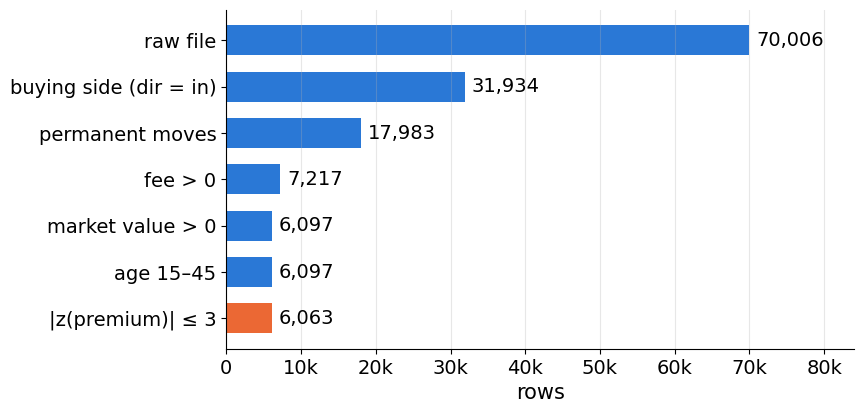

In [44]:
# Slide style: the figure size equals the space on the slide, so 14 pt here = 14 pt on screen
from matplotlib.ticker import FuncFormatter
plt.rcParams.update({"font.size": 14, "axes.titlesize": 16, "axes.labelsize": 15,
                     "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 13})

# Cleaning funnel (slide 2): short step names, final sample highlighted
short_steps = ["raw file", "buying side (dir = in)", "permanent moves", "fee > 0",
               "market value > 0", "age 15–45", "|z(premium)| ≤ 3"]
assert len(short_steps) == len(funnel_df)
fig, ax = plt.subplots(figsize=(8.1, 4.4))
y = np.arange(len(funnel_df))[::-1]                         # first step at the top
colors = [COLORS[0]] * (len(funnel_df) - 1) + [COLORS[1]]   # last bar = final sample
ax.barh(y, funnel_df["rows"], color=colors, height=0.65)
for yi, n in zip(y, funnel_df["rows"]):
    ax.text(n + 900, yi, f"{n:,}", va="center", fontsize=14)
ax.set_yticks(y)
ax.set_yticklabels(short_steps)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: "0" if v == 0 else f"{v/1000:.0f}k"))   # 20000 -> 20k
ax.set_xlim(0, funnel_df["rows"].max() * 1.2)
ax.set_xlabel("rows")
ax.grid(axis="y", visible=False)
save_fig(fig, "slide_fig01_cleaning_funnel.png")

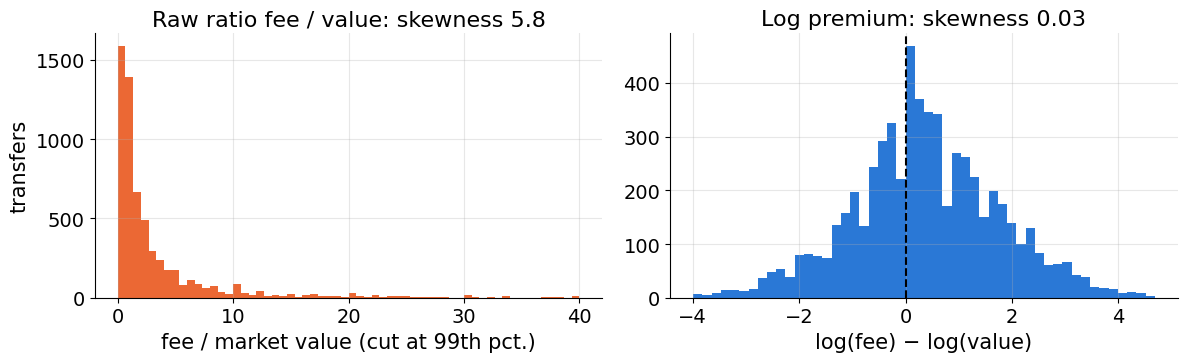

In [45]:
# Raw ratio vs log premium (slide 3): no super-title, skewness in the panel titles
fig, ax = plt.subplots(1, 2, figsize=(12.1, 3.85))
ax[0].hist(d["ratio"], bins=60, range=(0, d["ratio"].quantile(0.99)), color=COLORS[1])
ax[0].set_title(f"Raw ratio fee / value: skewness {sk_ratio:.1f}")
ax[0].set_xlabel("fee / market value (cut at 99th pct.)")
ax[0].set_ylabel("transfers")
ax[1].hist(d["premium"], bins=50, color=COLORS[0])
ax[1].axvline(0, color="black", ls="--", lw=1.5)           # fee = market value
ax[1].set_title(f"Log premium: skewness {sk_prem:.2f}")
ax[1].set_xlabel("log(fee) − log(value)")
fig.tight_layout()
save_fig(fig, "slide_fig02_ratio_vs_premium.png")

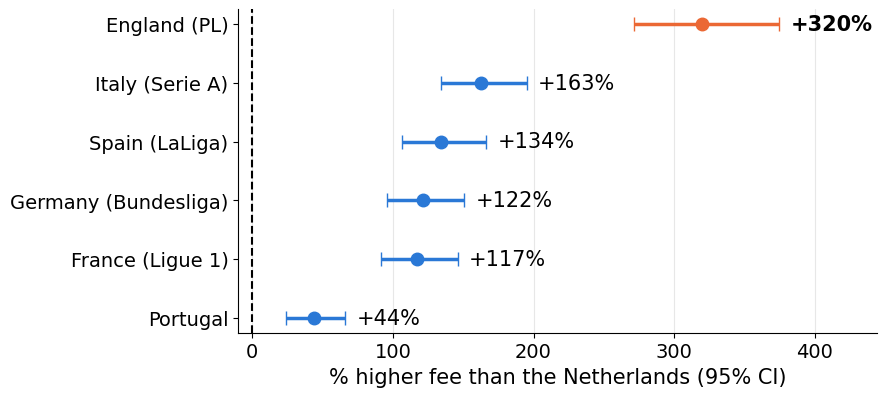

In [46]:
# League effects (slide 4): labels to the right of each interval so they cannot hit the title;
# England drawn in the accent colour because it is the finding of the slide
fig, ax = plt.subplots(figsize=(8.25, 4.2))
y = np.arange(len(lg))
for yi, (_, r) in zip(y, lg.iterrows()):
    c = COLORS[1] if r["league"] == "England" else COLORS[0]
    ax.errorbar(r["pct"], yi, xerr=[[r["pct"] - r["pct_lo"]], [r["pct_hi"] - r["pct"]]],
                fmt="o", color=c, ms=9, capsize=5, lw=2.5)
    ax.text(r["pct_hi"] + 8, yi, f"{r['pct']:+.0f}%", va="center", fontsize=15,
            fontweight="bold" if r["league"] == "England" else "normal")
ax.axvline(0, color="black", ls="--", lw=1.5)
ax.set_yticks(y)
ax.set_yticklabels([LEAGUE_LABEL[l] for l in lg["league"]])
ax.set_xlim(-10, lg["pct_hi"].max() + 70)
ax.set_xlabel("% higher fee than the Netherlands (95% CI)")
ax.grid(axis="y", visible=False)
save_fig(fig, "slide_fig04_league_effects_main.png")

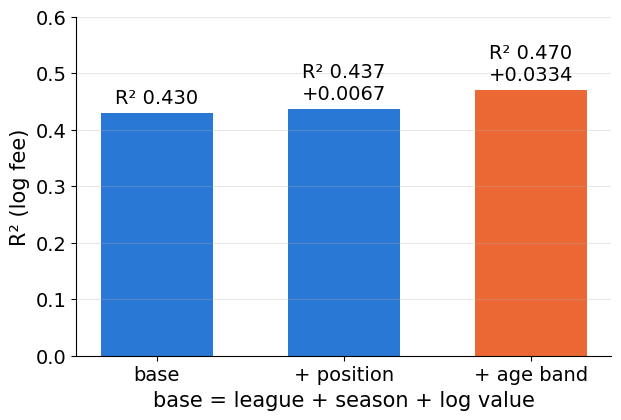

In [47]:
# R² contribution (slide 6): gains written on the bars
fig, ax = plt.subplots(figsize=(6.9, 4.4))
vals = r2["R2"].iloc[:3].values
ax.bar(range(3), vals, color=[COLORS[0], COLORS[0], COLORS[1]], width=0.6)
notes = [f"R² {vals[0]:.3f}", f"R² {vals[1]:.3f}\n+{dR2_pos:.4f}", f"R² {vals[2]:.3f}\n+{dR2_age:.4f}"]
for i, t in enumerate(notes):
    ax.text(i, vals[i] + 0.01, t, ha="center", va="bottom", fontsize=14)
ax.set_xticks(range(3))
ax.set_xticklabels(["base", "+ position", "+ age band"])
ax.set_xlabel("base = league + season + log value")
ax.set_ylabel("R² (log fee)")
ax.set_ylim(0, 0.6)
ax.grid(axis="x", visible=False)
save_fig(fig, "slide_fig12_r2_contribution.png")

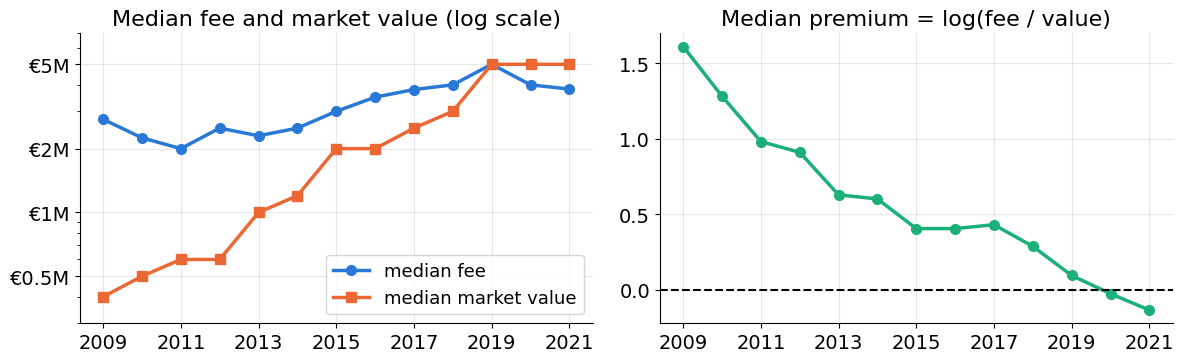

In [48]:
# Trends by season (slide 7): readable euro ticks on the log axis
fig, ax = plt.subplots(1, 2, figsize=(12.1, 3.85))
ax[0].plot(season_tab.index, season_tab["median_fee"] / 1e6, "o-", color=COLORS[0], lw=2.5, ms=7, label="median fee")
ax[0].plot(season_tab.index, season_tab["median_value"] / 1e6, "s-", color=COLORS[1], lw=2.5, ms=7, label="median market value")
ax[0].set_yscale("log")                                          # equal steps = equal % changes
ticks = [0.25, 0.5, 1, 2, 5]
ax[0].set_yticks(ticks)
ax[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"€{v:g}M"))
ax[0].yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))   # hide unlabelled minor ticks' text
ax[0].set_ylim(0.3, 7)
ax[0].set_title("Median fee and market value (log scale)")
ax[0].legend(loc="lower right")
ax[1].plot(season_tab.index, season_tab["median_premium"], "o-", color=COLORS[2], lw=2.5, ms=7)
ax[1].axhline(0, color="black", ls="--", lw=1.5)
ax[1].set_title("Median premium = log(fee / value)")
for a in ax:
    a.set_xticks(range(2009, 2022, 2))
fig.tight_layout()
save_fig(fig, "slide_fig15_trends_by_season.png")

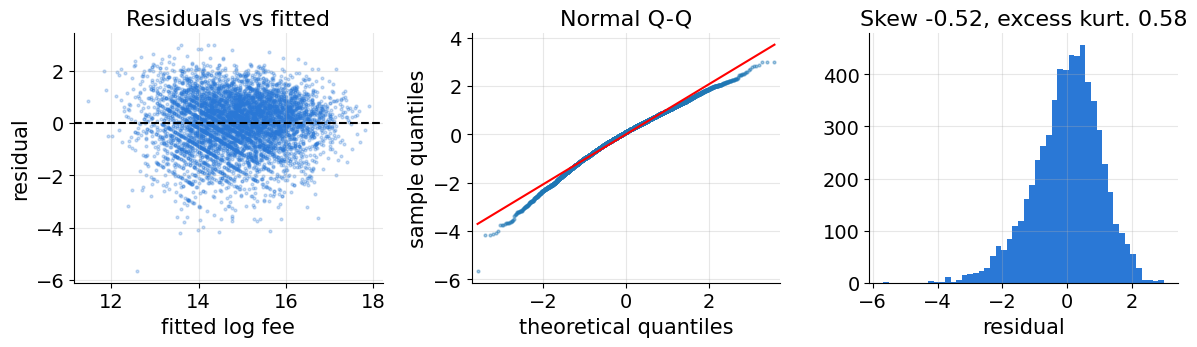

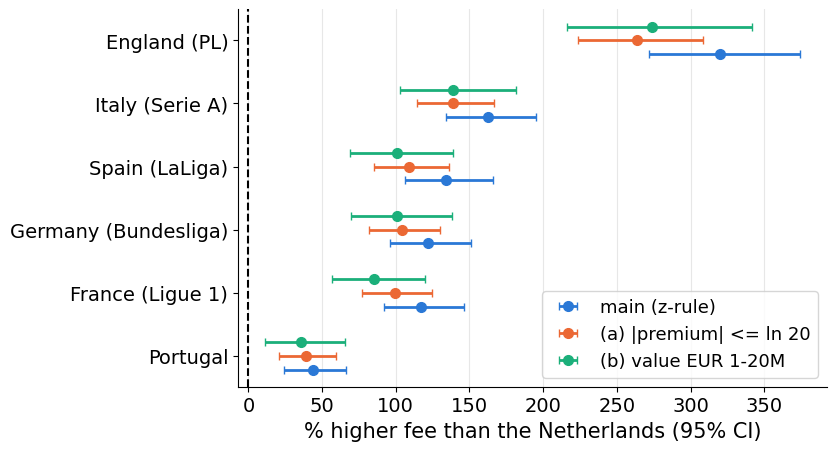

In [49]:
# Assumption checks (backup slide): same three panels, larger text, short titles
fig, ax = plt.subplots(1, 3, figsize=(12.1, 3.7))
ax[0].scatter(fitted, resid, s=4, alpha=0.25, color=COLORS[0])
ax[0].axhline(0, color="black", ls="--")
ax[0].set_xlabel("fitted log fee"); ax[0].set_ylabel("residual")
ax[0].set_title("Residuals vs fitted")
sm.qqplot(resid, line="s", ax=ax[1], markersize=2, alpha=0.4)
ax[1].set_title("Normal Q-Q")
ax[1].set_xlabel("theoretical quantiles"); ax[1].set_ylabel("sample quantiles")
ax[2].hist(resid, bins=50, color=COLORS[0])
ax[2].set_title(f"Skew {stats.skew(resid):.2f}, excess kurt. {stats.kurtosis(resid):.2f}")
ax[2].set_xlabel("residual")
fig.tight_layout()
save_fig(fig, "slide_fig05_assumption_checks.png")

# Robustness (backup slide)
fig, ax = plt.subplots(figsize=(7.6, 4.9))
for i, g in enumerate(ROB_ORDER):
    t = rob[rob["subgroup"] == g].set_index("league").reindex(leagues_nl)
    yy = np.arange(len(leagues_nl)) + (i - 1) * 0.22
    ax.errorbar(t["pct"], yy, xerr=[t["pct"] - t["pct_lo"], t["pct_hi"] - t["pct"]], fmt="o",
                color=COLORS[i], ms=7, capsize=3, lw=2, label=g)
ax.axvline(0, color="black", ls="--", lw=1.5)
ax.set_yticks(range(len(leagues_nl))); ax.set_yticklabels([LEAGUE_LABEL[l] for l in leagues_nl])
ax.set_xlabel("% higher fee than the Netherlands (95% CI)")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "slide_fig18_robustness.png")

In [50]:
# Network with all selling-only countries merged into ONE node.
# G (section 8) already has the self-loops removed, so this is cross-border transfers only.
OTHER = "Other sellers"
Gc = nx.DiGraph()
for u, v, e in G.edges(data=True):
    u2 = u if u in BUYERS else OTHER                 # any non-buying country becomes "Other sellers"
    if Gc.has_edge(u2, v):
        Gc[u2][v]["count"] += e["count"]
        Gc[u2][v]["fee"] += e["fee"]
    else:
        Gc.add_edge(u2, v, count=e["count"], fee=e["fee"])

merged = pd.DataFrame({
    "in_strength_n": dict(Gc.in_degree(weight="count")),     # transfers bought (cross-border)
    "out_strength_n": dict(Gc.out_degree(weight="count")),   # transfers sold to the 7 leagues
})
merged["from_other_sellers"] = [Gc[OTHER][n]["count"] if Gc.has_edge(OTHER, n) else 0 for n in merged.index]
merged["share_from_other_sellers"] = merged["from_other_sellers"] / merged["in_strength_n"]
merged = merged.sort_values("in_strength_n", ascending=False)
print(f"nodes: {Gc.number_of_nodes()} | edges: {Gc.number_of_edges()} | "
      f"cross-border transfers: {sum(nx.get_edge_attributes(Gc, 'count').values()):,}")
print(f"'{OTHER}' sends {merged.loc[OTHER, 'out_strength_n']:,} transfers "
      f"from {len([n for n in G.nodes if n not in BUYERS])} countries")
print(merged.drop(index=OTHER).round(3).to_string())
save_table(merged, "network_merged_other_sellers.csv")

nodes: 8 | edges: 49 | cross-border transfers: 3,292
'Other sellers' sends 1,702 transfers from 73 countries
             in_strength_n  out_strength_n  from_other_sellers  share_from_other_sellers
Italy                  707             210                 424                     0.600
England                678             262                 247                     0.364
Germany                518             188                 293                     0.566
Spain                  467             279                 182                     0.390
France                 444             298                 222                     0.500
Portugal               274             182                 192                     0.701
Netherlands            204             171                 142                     0.696


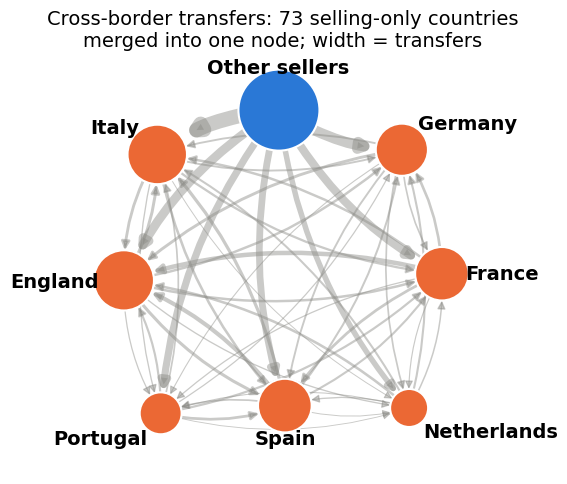

In [51]:
# Figure (slide 8): Fruchterman-Reingold layout with a fixed seed; every edge is drawn.
# node size = total strength (in + out), edge width = number of transfers, curved so A->B and B->A separate
pos_c = nx.spring_layout(Gc.to_undirected(), weight=None, seed=SEED, k=1.6, iterations=300)
tot = {n: merged.loc[n, "in_strength_n"] + merged.loc[n, "out_strength_n"] for n in Gc.nodes()}
max_c = max(nx.get_edge_attributes(Gc, "count").values())
size = [tot[n] * 2.0 for n in Gc.nodes()]
width = [0.6 + 10 * e["count"] / max_c for _, _, e in Gc.edges(data=True)]
node_col = [COLORS[0] if n == OTHER else COLORS[1] for n in Gc.nodes()]

fig, ax = plt.subplots(figsize=(6.5, 5.45))
nx.draw_networkx_edges(Gc, pos_c, ax=ax, width=width, alpha=0.45, edge_color=GREY, arrows=True,
                       arrowsize=12, connectionstyle="arc3,rad=0.15", node_size=size)
nx.draw_networkx_nodes(Gc, pos_c, ax=ax, node_size=size, node_color=node_col, edgecolors="white", linewidths=1.5)
# labels sit just outside each node, pushed away from the centre of the layout, so they never cover a node
centre = np.mean(list(pos_c.values()), axis=0)
for n, (x, y) in pos_c.items():
    dx, dy = np.array([x, y]) - centre
    r = np.hypot(dx, dy)
    ux, uy = dx / r, dy / r                           # unit direction away from the centre
    off = 0.10 + 0.00006 * tot[n]                     # bigger node -> label further out
    ha = "left" if ux > 0.35 else "right" if ux < -0.35 else "center"   # text grows away from the node
    va = "bottom" if uy > 0.35 else "top" if uy < -0.35 else "center"
    ax.text(x + off * ux, y + off * uy, "Other sellers" if n == OTHER else n,
            ha=ha, va=va, fontsize=14, fontweight="bold", color="black")
ax.set_title(f"Cross-border transfers: {len([n for n in G.nodes if n not in BUYERS])} selling-only countries\n"
             "merged into one node; width = transfers", fontsize=14)
ax.margins(x=0.22, y=0.12)
ax.axis("off")
save_fig(fig, "slide_fig17_network_merged.png")

### Takeaway
* Eight figures are redrawn at their slide size and saved as `figures/slide_*.png`. Fixes: the league-effect labels now sit to the right of each interval (no overlap with the title), and the log axis of the fee/value trend has euro tick labels (€0.5M … €5M).
* Merged network: **8 nodes and 49 edges** carrying the **3,292** cross-border transfers. The node "Other sellers" groups **73** selling-only countries and sends **1,702** transfers.
* Share of each league's cross-border purchases that come from "Other sellers": **Portugal 70.1 %, Netherlands 69.6 %, Italy 60.0 %, Germany 56.6 %, France 50.0 %, Spain 39.0 %, England 36.4 %.**